# 05 — Final scientific comparison of models, ablations, and reliability

<style>
.jp-RenderedHTMLCommon, .jp-RenderedMarkdown, .rendered_html {
  font-size: 18px !important;
  line-height: 1.58 !important;
  max-width: none !important;
}
.jp-RenderedHTMLCommon table, .rendered_html table, table.dataframe {
  font-size: 18px !important;
  line-height: 1.42 !important;
  border-collapse: collapse !important;
  width: auto !important;
  max-width: 100% !important;
}
.jp-RenderedHTMLCommon th, .jp-RenderedHTMLCommon td,
.rendered_html th, .rendered_html td {
  padding: 0.45em 0.65em !important;
  vertical-align: top !important;
}
.jp-OutputArea-output, .output_subarea { overflow-x: auto !important; }
.jp-RenderedHTMLCommon pre, .rendered_html pre { font-size: 17px !important; }
</style>

## 1. Environment and presentation utilities

In [1]:
from pathlib import Path
from collections import Counter
import json, math, re

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyArrowPatch, Patch
from matplotlib.text import Text
import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score
from IPython.display import Markdown, display

PROJECT = 'multilevel_semantic_knowledge_structuring'
candidates = list(Path.cwd().resolve().parents) + [Path.cwd().resolve()]
ROOT = next(
    path.resolve()
    for path in candidates
    if (path / 'Tasks_for_Codex.md').exists() and (path / 'dataset' / 'unified').exists()
)
TABLES = ROOT / 'results' / 'tables'
FIGURES = ROOT / 'results' / 'figures'
MODELS = ROOT / 'results' / 'models' / 'massk_artifacts'
DATA = ROOT / 'dataset' / 'unified'
for directory in [TABLES, FIGURES, MODELS]:
    directory.mkdir(parents=True, exist_ok=True)

MISSING = {
    'measured': 'NOT_MEASURED',
    'executed': 'NOT_EXECUTED',
    'applicable': 'NOT_APPLICABLE',
    'withheld': 'WITHHELD_BY_PROTOCOL',
    'pending': 'PENDING_CONFIRMATION',
}
PALETTE = {
    'blue': '#2F6B8F',
    'orange': '#C77C2B',
    'green': '#4F7F3A',
    'purple': '#6D5A8D',
    'red': '#B45A55',
    'gray': '#6E7378',
    'light_gray': '#E7EAED',
    'teal': '#4A8C8A',
    'gold': '#C9A227',
    'black': '#222222',
    'white': '#FFFFFF',
}
FONT_PATH = Path(font_manager.findfont('Times New Roman', fallback_to_default=False))
assert 'times' in FONT_PATH.name.lower(), f'Times New Roman not resolved: {FONT_PATH}'
mpl.rcParams.update(
    {
        'font.family': 'Times New Roman',
        'font.size': 18,
        'axes.titlesize': 20,
        'axes.labelsize': 19,
        'xtick.labelsize': 18,
        'ytick.labelsize': 18,
        'legend.fontsize': 18,
        'figure.titlesize': 20,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.unicode_minus': True,
        'savefig.dpi': 350,
        'figure.dpi': 350,
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
    }
)

In [2]:
FORBIDDEN_MISSING = {"", "nan", "na", "n/a", "none", "null", "not_available", "not available"}


def normalized_frame(frame, default_reason):
    clean = frame.copy().astype(object).replace([np.inf, -np.inf], default_reason)
    clean = clean.where(pd.notna(clean), default_reason)
    explicit = {
        "not_applicable": MISSING["applicable"],
        "not executed": MISSING["executed"],
        "not_executed": MISSING["executed"],
        "not measured": MISSING["measured"],
        "not_measured": MISSING["measured"],
        "pending": MISSING["pending"],
        "withheld": MISSING["withheld"],
    }
    for column in clean.columns:
        stripped = clean[column].map(
            lambda value: value.strip() if isinstance(value, str) else value
        )
        lowered = stripped.map(lambda value: value.lower() if isinstance(value, str) else value)
        clean[column] = [
            explicit.get(low, default_reason if low in FORBIDDEN_MISSING else value)
            for value, low in zip(stripped, lowered)
        ]
    return clean


def assert_explicit_missing(frame):
    assert not frame.isna().any().any()
    for column in frame.columns:
        values = frame[column].astype(str).str.strip().str.lower()
        assert not values.isin(FORBIDDEN_MISSING).any(), column


def save_table(frame, filename, default_reason=MISSING["measured"]):
    clean = normalized_frame(frame, default_reason)
    assert_explicit_missing(clean)
    path = TABLES / filename
    temporary = path.with_name("." + path.name + ".tmp")
    clean.to_csv(temporary, index=False)
    temporary.replace(path)
    return path, clean


def show_table(frame, rows=18, width=90):
    clean = normalized_frame(frame, MISSING["measured"])
    with pd.option_context(
        "display.max_columns",
        None,
        "display.max_rows",
        rows,
        "display.max_colwidth",
        width,
        "display.width",
        240,
    ):
        display(clean.head(rows))


def first_column(frame, aliases):
    if frame is None:
        return None
    lookup = {str(column).lower(): column for column in frame.columns}
    return next(
        (lookup[alias.lower()] for alias in aliases if alias.lower() in lookup),
        None,
    )

In [3]:
def relative_luminance(rgb):
    channels = [
        value / 12.92 if value <= 0.04045 else ((value + 0.055) / 1.055) ** 2.4 for value in rgb[:3]
    ]
    return 0.2126 * channels[0] + 0.7152 * channels[1] + 0.0722 * channels[2]


def contrast_choice(rgba):
    background = relative_luminance(rgba)
    black_ratio = (background + 0.05) / 0.05
    white_ratio = 1.05 / (background + 0.05)
    return ("black", black_ratio) if black_ratio >= white_ratio else ("white", white_ratio)


def annotate_matrix(ax, image, values, formatter, role=None):
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            color, ratio = contrast_choice(image.cmap(image.norm(values[row, column])))
            assert ratio >= 4.5
            ax.text(
                column,
                row,
                formatter(values[row, column]),
                ha="center",
                va="center",
                color=color,
                fontsize=18,
            )

In [4]:
def save_figure(fig, stem, role=None):
    png_path = FIGURES / f"{stem}.png"
    pdf_path = FIGURES / f"{stem}.pdf"
    fig.savefig(png_path, format="png", dpi=350, bbox_inches="tight", facecolor="white")
    fig.savefig(pdf_path, format="pdf", dpi=350, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


def withhold_figure(stem, role, status, reason):
    """Return the scientific reason why an unexecuted figure is not generated."""
    return {
        "stem": stem,
        "role": role,
        "status": status,
        "reason": reason,
    }

## 2. Load canonical development-validation results

In [5]:
REPORTING_MODEL = "SEMANTIC_ONLY"
SYNTHESIS_STATUS = "EXPLORATORY_DEVELOPMENT_VALIDATION"
FULL_MODEL_ELIGIBLE = False
ROUND7_PROTOCOL_ID = "massk_exploratory_round7_residual_anchor_2026_07_19"


def load_csv(relative_path):
    path = ROOT / relative_path
    return pd.read_csv(path, keep_default_na=False) if path.exists() else None


def load_parquet(relative_path):
    path = ROOT / relative_path
    return pd.read_parquet(path) if path.exists() else None

## 3. Dataset and split characteristics

In [6]:

dataset_audit = pd.read_csv(TABLES / 'dataset_audit_summary.csv', keep_default_na=False)
split_audit = pd.read_csv(TABLES / 'split_summary.csv', keep_default_na=False)
leakage_audit = pd.read_csv(TABLES / 'leakage_check_summary.csv', keep_default_na=False)
development = pd.read_parquet(DATA / 'development_dataset.parquet')
assert set(development['split']).issubset({'train', 'validation'})

final_dataset = dataset_audit.copy()
_, final_dataset = save_table(final_dataset, 'final_dataset_summary.csv')
split_rows = pd.DataFrame(
    {
        'section': 'Split composition',
        'item': split_audit[['split', 'source', 'thematic_class']]
        .astype(str)
        .agg(' · '.join, axis=1),
        'value': split_audit['records'],
        'status': 'Observed records',
    }
)
leakage_rows = pd.DataFrame(
    {
        'section': 'Cross-split identity check',
        'item': leakage_audit[['check', 'split_pair']].astype(str).agg(' · '.join, axis=1),
        'value': leakage_audit['violations'],
        'status': np.where(
            pd.to_numeric(leakage_audit['violations']).eq(0),
            'No violation detected',
            'Violation detected',
        ),
    }
)
final_split = pd.concat([split_rows, leakage_rows], ignore_index=True)
_, final_split = save_table(final_split, 'final_split_and_leakage_summary.csv')

corpus_summary = (
    split_audit.groupby(['split', 'source'], as_index=False)['records']
    .sum()
    .rename(columns={'split': 'Partition', 'source': 'Source', 'records': 'Publications'})
)
leakage_summary = (
    leakage_rows.groupby('status', as_index=False)['value']
    .sum()
    .rename(columns={'status': 'Result', 'value': 'Detected violations'})
)
display(
    corpus_summary.style.hide(axis='index')
    .format({'Publications': '{:,.0f}'})
    .set_caption('Corpus composition by partition and source')
)
display(
    leakage_summary.style.hide(axis='index')
    .format({'Detected violations': '{:,.0f}'})
    .set_caption('Cross-split identity and duplicate checks')
)


Partition,Source,Publications
external_test,arxiv,"1,181"
test,openalex,"1,914"
train,openalex,"3,825"
validation,arxiv,"1,176"
validation,openalex,"1,707"


Result,Detected violations
No violation detected,0


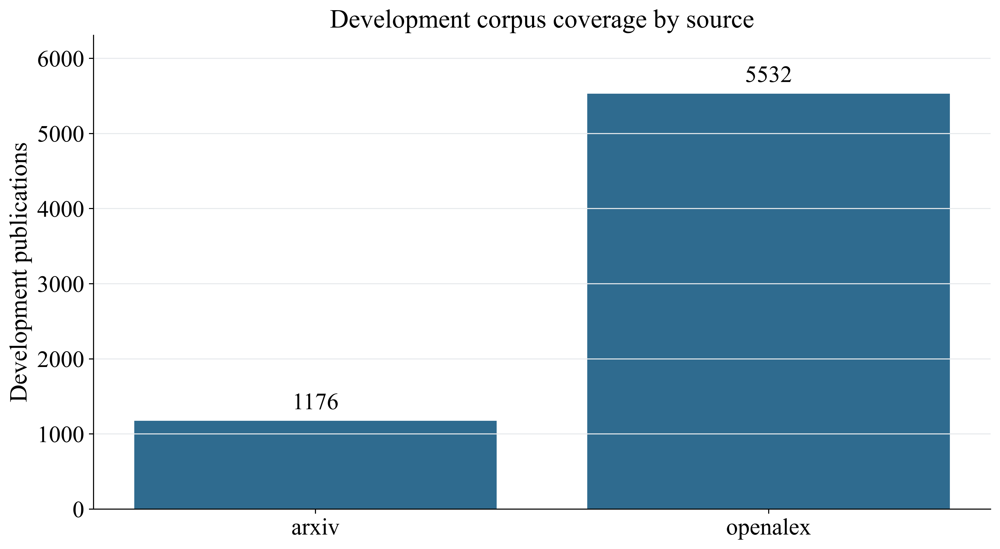

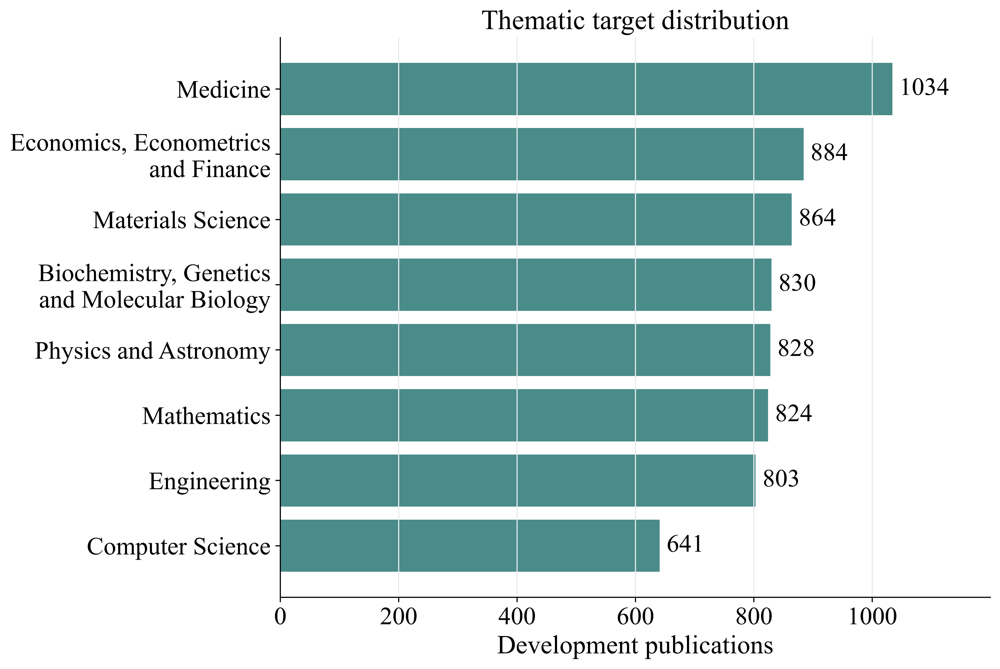

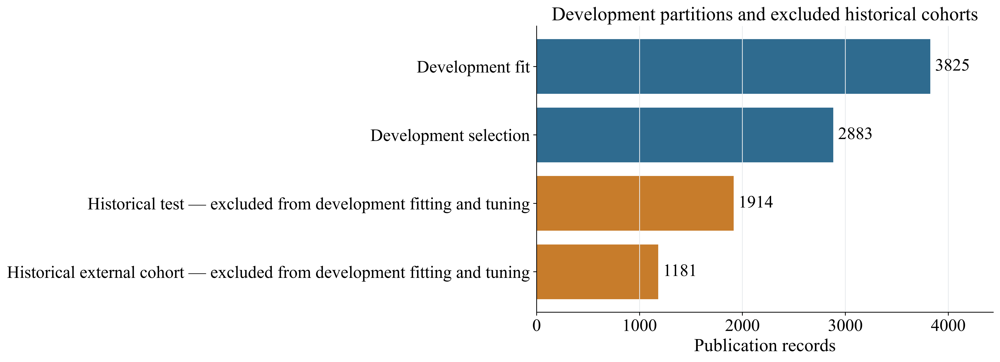

In [7]:
coverage = development.groupby('source', as_index=False).size().rename(columns={'size': 'papers'})
fig, ax = plt.subplots(figsize=(11.0, 6.2))
bars = ax.bar(coverage['source'], coverage['papers'], color=PALETTE['blue'])
ax.bar_label(bars, fmt='%d', fontsize=18, padding=5)
ax.set_ylabel('Development publications')
ax.set_title('Development corpus coverage by source')
ax.grid(axis='y', color=PALETTE['light_gray'])
ax.set_ylim(0, coverage['papers'].max() * 1.14)
fig.tight_layout()
save_figure(fig, 'dataset_coverage', 'dataset_source_coverage')

target_counts = development['thematic_class'].value_counts().sort_values()
target_display = {
    'Biochemistry, Genetics and Molecular Biology': 'Biochemistry, Genetics\nand Molecular Biology',
    'Economics, Econometrics and Finance': 'Economics, Econometrics\nand Finance',
    'Materials Science': 'Materials Science',
    'Physics and Astronomy': 'Physics and Astronomy',
}
target_labels = [target_display.get(label, label) for label in target_counts.index]
fig, ax = plt.subplots(figsize=(10.8, 7.4))
bars = ax.barh(target_labels, target_counts.values, color=PALETTE['teal'])
ax.bar_label(bars, fmt='%d', fontsize=18, padding=5)
ax.set_xlabel('Development publications')
ax.set_title('Thematic target distribution')
ax.grid(axis='x', color=PALETTE['light_gray'])
ax.set_xlim(0, target_counts.max() * 1.16)
fig.subplots_adjust(left=0.31, right=0.97, bottom=0.12, top=0.88)
save_figure(fig, 'target_distribution', 'target_distribution')

split_counts = split_audit.groupby('split', as_index=False)['records'].sum().sort_values('records')
split_display = {
    'train': 'Development fit',
    'validation': 'Development selection',
    'test': 'Historical test — excluded from development fitting and tuning',
    'external_test': 'Historical external cohort — excluded from development fitting and tuning',
}
split_counts['display_label'] = (
    split_counts['split'].map(split_display).fillna(split_counts['split'])
)
colors = [
    PALETTE['orange'] if 'excluded' in value.lower() else PALETTE['blue']
    for value in split_counts['display_label']
]
fig, ax = plt.subplots(figsize=(10.8, 6.0))
bars = ax.barh(split_counts['display_label'], split_counts['records'], color=colors)
ax.bar_label(bars, fmt='%d', fontsize=18, padding=5)
ax.set_xlabel('Publication records')
ax.set_title('Development partitions and excluded historical cohorts')
ax.grid(axis='x', color=PALETTE['light_gray'])
ax.set_xlim(0, split_counts['records'].max() * 1.16)
fig.subplots_adjust(left=0.36, right=0.97, bottom=0.15, top=0.84)
save_figure(fig, 'split_design', 'split_design_counts_only')

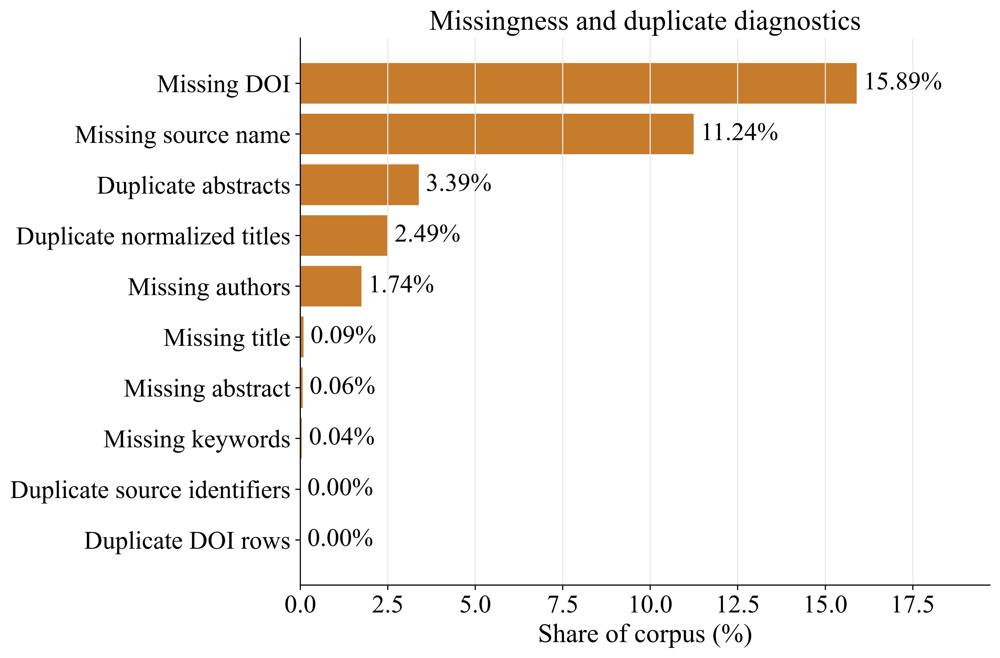

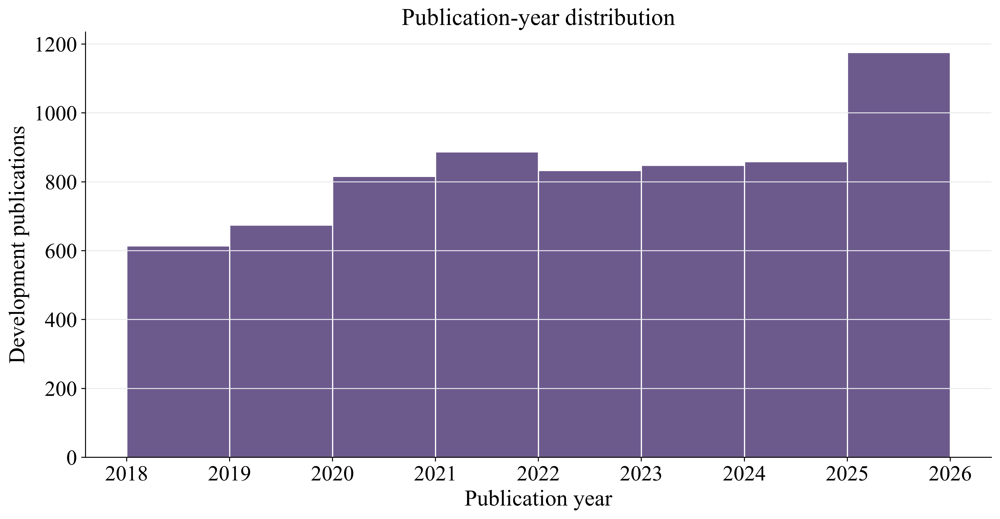

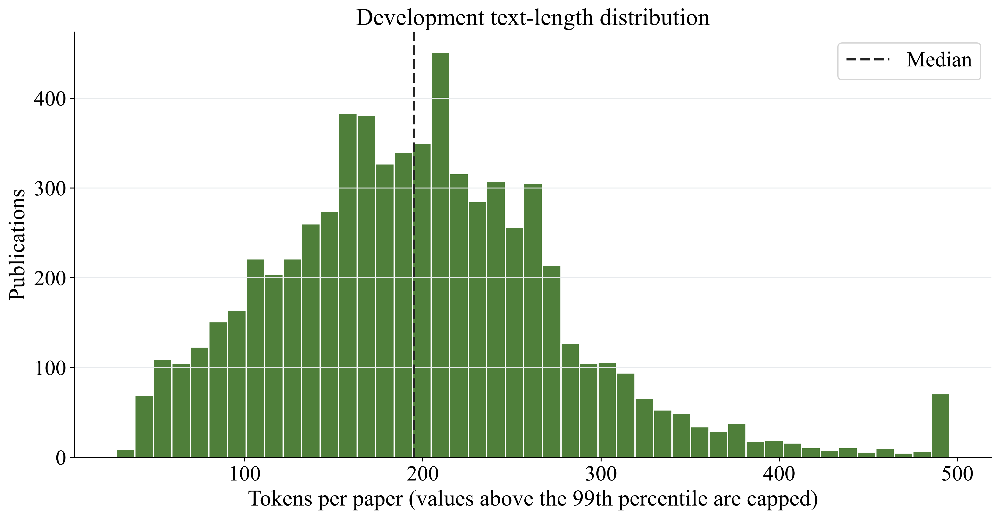

In [8]:
missing = pd.read_csv(TABLES / 'missingness_duplicate_summary.csv', keep_default_na=False)
missing['rate_numeric'] = pd.to_numeric(missing['rate'], errors='coerce')
plot_missing = missing.dropna(subset=['rate_numeric']).sort_values('rate_numeric').tail(12)
diagnostic_labels = {
    'missing_title': 'Missing title',
    'missing_abstract': 'Missing abstract',
    'missing_doi': 'Missing DOI',
    'missing_keywords': 'Missing keywords',
    'missing_source_name': 'Missing source name',
    'missing_authors': 'Missing authors',
    'duplicate_doi_rows': 'Duplicate DOI rows',
    'duplicate_normalized_title_rows': 'Duplicate normalized titles',
    'duplicate_abstract_hash_rows': 'Duplicate abstracts',
    'duplicate_source_id_rows': 'Duplicate source identifiers',
}
plot_missing['display_metric'] = (
    plot_missing['metric'].map(diagnostic_labels).fillna(plot_missing['metric'])
)
fig, ax = plt.subplots(figsize=(10.8, 7.2))
bars = ax.barh(
    plot_missing['display_metric'], 100 * plot_missing['rate_numeric'], color=PALETTE['orange']
)
ax.bar_label(
    bars,
    labels=[f'{value:.2f}%' for value in 100 * plot_missing['rate_numeric']],
    fontsize=18,
    padding=5,
)
ax.set_xlabel('Share of corpus (%)')
ax.set_title('Missingness and duplicate diagnostics')
ax.grid(axis='x', color=PALETTE['light_gray'])
ax.set_xlim(0, max(0.01, 100 * plot_missing['rate_numeric'].max()) * 1.24)
fig.subplots_adjust(left=0.34, right=0.97, bottom=0.13, top=0.88)
save_figure(fig, 'missingness_and_duplicates', 'missingness_duplicates')

years = pd.to_numeric(development['publication_year'], errors='coerce').dropna()
fig, ax = plt.subplots(figsize=(12.0, 6.4))
ax.hist(years, bins=min(28, int(years.nunique())), color=PALETTE['purple'], edgecolor='white')
ax.set_xlabel('Publication year')
ax.set_ylabel('Development publications')
ax.set_title('Publication-year distribution')
ax.grid(axis='y', color=PALETTE['light_gray'])
fig.tight_layout()
save_figure(fig, 'publication_year_distribution', 'publication_year_distribution')

tokens = pd.to_numeric(development['token_count'], errors='coerce').dropna()
upper = float(tokens.quantile(0.99))
shown = tokens.clip(upper=upper)
fig, ax = plt.subplots(figsize=(12.0, 6.4))
ax.hist(shown, bins=45, color=PALETTE['green'], edgecolor='white')
ax.axvline(tokens.median(), color=PALETTE['black'], linewidth=2.2, linestyle='--', label='Median')
ax.set_xlabel('Tokens per paper (values above the 99th percentile are capped)')
ax.set_ylabel('Publications')
ax.set_title('Development text-length distribution')
ax.grid(axis='y', color=PALETTE['light_gray'])
ax.legend(loc='upper right', frameon=True, facecolor='white')
fig.tight_layout()
save_figure(fig, 'text_length_distribution', 'text_length_distribution')

## 4. Current model comparison on the common validation panel

The complete table contains 19 models evaluated on the same 6,708 development publications. The class-wise retrieval residual is the current exploratory point leader on 10/12 metrics. Its classification gain is not confirmed; its NLL and Brier improvements over PRISM are supported by paper- and proxy-cluster intervals. The receipt-backed core is the frozen historical reference; no current model has confirmatory performance evidence.

In [9]:
metrics_raw = load_csv('results/tables/massk_metrics.csv')
predictions = load_parquet('results/tables/massk_paper_level_predictions.parquet')
exact_raw = load_csv('results/tables/round7_resource_bounded_exact_fold_panel.csv')
calibration_raw = load_csv('results/tables/massk_round7_calibration_selected_state.csv')
structural_raw = load_csv('results/tables/massk_structural_outer_metrics.csv')
robustness_raw = load_csv('results/tables/modality_robustness_validation.csv')
efficiency_raw = load_csv('results/tables/massk_round7_efficiency_accounting.csv')
residual_raw = load_parquet('results/tables/massk_round7_residual_gate_strength_outer.parquet')
statistics_raw = load_csv('results/tables/statistical_tests.csv')
outer_fold_metrics = load_csv('results/tables/track_outer_metrics.csv')
fold_assignments = load_parquet('results/tables/nested_fold_assignments.parquet')
profiles_raw = load_parquet('results/tables/massk_round7_semantic_profiles.parquet')


def list_value(value):
    if isinstance(value, (list, tuple, np.ndarray)):
        return list(value)
    if isinstance(value, str):
        try:
            return list(json.loads(value))
        except (json.JSONDecodeError, TypeError):
            return []
    return []


profile_records = []
if profiles_raw is not None and predictions is not None:
    profile_predictions = predictions[predictions['track'].eq(REPORTING_MODEL)].copy()
    probability_columns = sorted(
        [column for column in profile_predictions if re.fullmatch(r'probability_\d+', str(column))],
        key=lambda column: int(str(column).rsplit('_', 1)[1]),
    )
    label_map = (
        development[['label_id', 'thematic_class']]
        .drop_duplicates()
        .set_index('label_id')['thematic_class']
        .to_dict()
    )
    profile_predictions = profile_predictions.set_index('sample_id')
    metadata_by_sample = development.set_index('sample_id')
    uncertainties = 1 - profile_predictions[probability_columns].max(axis=1)
    risk_low, risk_high = uncertainties.quantile([1 / 3, 2 / 3])
    for sample_id, group in profiles_raw.groupby('sample_id', sort=False):
        if sample_id not in profile_predictions.index:
            continue
        prediction = profile_predictions.loc[sample_id]
        paper = metadata_by_sample.loc[sample_id]
        probabilities = prediction[probability_columns].to_numpy(dtype=float)
        ranking = np.argsort(-probabilities)[:3]
        concept_rank, neighbor_scores = {}, {}
        for concepts in group['key_concepts'].map(list_value):
            for rank, concept in enumerate(concepts):
                concept_rank.setdefault(str(concept), []).append(rank)
        for row in group.itertuples(index=False):
            for neighbor, score in zip(
                list_value(row.semantic_neighbors), list_value(row.fused_retrieval_scores)
            ):
                neighbor_scores[str(neighbor)] = max(
                    float(score), neighbor_scores.get(str(neighbor), -np.inf)
                )
        concepts = sorted(
            concept_rank,
            key=lambda value: (-len(concept_rank[value]), np.mean(concept_rank[value]), value),
        )[:10]
        neighbors = sorted(neighbor_scores.items(), key=lambda item: (-item[1], item[0]))[:10]
        predicted_label, true_label = int(probabilities.argmax()), int(prediction['true_label'])
        uncertainty = float(1 - probabilities.max())
        relative_risk = (
            'low' if uncertainty <= risk_low else ('medium' if uncertainty <= risk_high else 'high')
        )
        profile_records.append(
            {
                'sample_id': sample_id,
                'source': str(paper['source']),
                'paper_id': str(paper['paper_id']),
                'title': str(paper['title_raw']),
                'publication_year': int(paper['publication_year']),
                'source_name': str(paper['source_name']).strip() or 'NOT_AVAILABLE_SOURCE_NAME',
                'language': str(paper['language']),
                'development_row_index': int(group['development_row_index'].iloc[0]),
                'protocol_id': ROUND7_PROTOCOL_ID,
                'reporting_model': REPORTING_MODEL,
                'evidence_scope': 'EXPLORATORY_POST_SELECTION_DEVELOPMENT_VALIDATION',
                'reference_label': true_label,
                'true_thematic_class': label_map[true_label],
                'predicted_label': predicted_label,
                'predicted_thematic_class': label_map[predicted_label],
                'probabilities': probabilities.tolist(),
                'calibrated_probability': float(probabilities.max()),
                'top_k_predicted_classes': [
                    {
                        'label_id': int(label),
                        'thematic_class': label_map[int(label)],
                        'probability': float(probabilities[label]),
                    }
                    for label in ranking
                ],
                'key_concepts': concepts,
                'semantic_neighbors': [neighbor for neighbor, score in neighbors],
                'semantic_similarity_scores': [float(score) for neighbor, score in neighbors],
                'confidence_score': float(probabilities.max()),
                'uncertainty_score': uncertainty,
                'uncertainty_method': 'one_minus_confidence_round7_profile',
                'risk_category': relative_risk,
                'calibration_method': 'identity',
                'metadata_summary': {
                    'doi': str(paper['doi']).strip() or 'NOT_AVAILABLE_DOI',
                    'author_count': int(paper['author_count']),
                    'cited_by_count': (
                        None if pd.isna(paper['cited_by_count']) else float(paper['cited_by_count'])
                    ),
                    'open_access': bool(paper['open_access']),
                },
            }
        )
    assert len(profile_records) == development['sample_id'].nunique()
    profile_path = DATA / 'semantic_profiles.jsonl'
    temporary = DATA / '.semantic_profiles.jsonl.tmp'
    with temporary.open('w', encoding='utf-8') as stream:
        for record in profile_records:
            stream.write(json.dumps(record, ensure_ascii=False) + '\n')
    temporary.replace(profile_path)
    examples = pd.DataFrame(profile_records[:12]).drop(columns=['probabilities'])
    for column in [
        'top_k_predicted_classes',
        'key_concepts',
        'semantic_neighbors',
        'semantic_similarity_scores',
        'metadata_summary',
    ]:
        examples[column] = examples[column].map(lambda value: json.dumps(value, ensure_ascii=False))
    _, profile_examples = save_table(
        examples, 'semantic_profile_examples.csv', MISSING['applicable']
    )
    reader_examples = pd.DataFrame(profile_records[:4])[
        [
            'title',
            'true_thematic_class',
            'predicted_thematic_class',
            'confidence_score',
            'key_concepts',
            'semantic_neighbors',
        ]
    ].copy()
    reader_examples['title'] = reader_examples['title'].str.slice(0, 100)
    reader_examples['key_concepts'] = reader_examples['key_concepts'].map(
        lambda values: '; '.join(map(str, values[:4]))
    )
    reader_examples['semantic_neighbors'] = reader_examples['semantic_neighbors'].map(
        lambda values: '; '.join(map(str, values[:3]))
    )
    reader_examples = reader_examples.rename(
        columns={
            'title': 'Paper title',
            'true_thematic_class': 'Reference field',
            'predicted_thematic_class': 'Predicted field',
            'confidence_score': 'Confidence',
            'key_concepts': 'Key concepts',
            'semantic_neighbors': 'Retrieved evidence',
        }
    )
    display(
        reader_examples.style.hide(axis='index')
        .format({'Confidence': '{:.3f}'})
        .set_properties(
            subset=['Paper title', 'Key concepts', 'Retrieved evidence'],
            **{'max-width': '330px', 'white-space': 'normal'},
        )
        .set_caption('Four representative semantic profiles')
    )

Paper title,Reference field,Predicted field,Confidence,Key concepts,Retrieved evidence
Pakcoy Plant Sprinklers Based Internet Of Things,Computer Science,Computer Science,0.606,artificial intelligence; business; environmental science; telecommunications,openalex:W4405910026; openalex:W4239447898; openalex:W3191282910
Assessment of the Acceptance of Internet of Things Technology in the Health Field Using TAM2: A Surv,Computer Science,Computer Science,0.541,psychology; business; political science; sociology,openalex:W4409602966; openalex:W3123270788; openalex:W4281755612
The notion of ‘Open Science’: its values and meaning for the higher education system,Computer Science,"Economics, Econometrics and Finance",0.404,political science; business; sociology; law,openalex:W3117481674; openalex:W4387188007; openalex:W4404016764
PEMEROLEHAN BAHASA PADA ANAK DENGAN AUTISM SPECTRUM DISORDERS (ASD),Computer Science,Computer Science,0.722,psychology; artificial intelligence; linguistics; surgery,openalex:W4313405496; openalex:W4312655700; openalex:W4308353686


In [10]:
EXPLORATORY_VALIDATION_CANDIDATE = 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL'
PRIMARY_METRICS = {
    'accuracy': ('Accuracy ↑', 'max'),
    'balanced_accuracy': ('Balanced accuracy ↑', 'max'),
    'macro_f1': ('Macro-F1 ↑', 'max'),
    'weighted_f1': ('Weighted-F1 ↑', 'max'),
    'macro_precision': ('Macro precision ↑', 'max'),
    'macro_recall': ('Macro recall ↑', 'max'),
    'mcc': ('MCC ↑', 'max'),
}
RELIABILITY_METRICS = {
    'nll': ('NLL ↓', 'min'),
    'ece_15': ('ECE-15 ↓', 'min'),
    'brier_multiclass': ('Multiclass Brier ↓', 'min'),
    'error_auroc': ('Error AUROC ↑', 'max'),
    'aurc': ('AURC ↓', 'min'),
}
all_specs = {**PRIMARY_METRICS, **RELIABILITY_METRICS}

r14_paths = {
    "comparison": TABLES / "massk_round14_model_comparison.csv",
    "gate": TABLES / "massk_round14_statistical_gate.csv",
    "reliability": TABLES / "massk_round14_secondary_reliability_tests.csv",
    "predictions": TABLES / "massk_round14_paper_predictions.parquet",
}
assert all(path.exists() for path in r14_paths.values())
r14_gate = pd.read_csv(r14_paths['gate'], keep_default_na=False)
r14_reliability = pd.read_csv(r14_paths['reliability'], keep_default_na=False)
round14_paper = pd.read_parquet(r14_paths['predictions'])
assert len(round14_paper) == len(development) and round14_paper.sample_id.nunique() == len(
    development
)
assert not bool(r14_gate.loc[0, 'scientific_gate_pass'])
assert r14_reliability.paper_interval_supports_improvement.all()
assert r14_reliability.cluster_interval_supports_improvement.all()

final_model = pd.read_csv(
    TABLES / 'final_model_comparison_with_refinement14.csv', keep_default_na=False
)
assert len(final_model) == 19 and final_model.model.is_unique
panel = final_model.copy()
panel['track'] = panel['model']
MODEL_LABELS = final_model.set_index('model').model_label.to_dict()
_, final_model = save_table(final_model, 'final_model_comparison.csv', MISSING['applicable'])
primary_table = final_model[['model_label', *PRIMARY_METRICS]].rename(
    columns={m: l for m, (l, _) in PRIMARY_METRICS.items()}
)
reliability_table = final_model[['model_label', *RELIABILITY_METRICS]].rename(
    columns={m: l for m, (l, _) in RELIABILITY_METRICS.items()}
)
_, primary_table = save_table(primary_table, 'model_metric_comparison_primary.csv')
_, reliability_table = save_table(reliability_table, 'model_metric_comparison_reliability.csv')

winner_rows = []
for metric, (label, direction) in all_specs.items():
    ordered = final_model.sort_values(metric, ascending=direction == 'min')
    best, second = ordered.iloc[0], ordered.iloc[1]
    winner_rows.append(
        {
            'metric': label,
            'winner': best.model_label,
            'best_value': float(best[metric]),
            'runner_up': second.model_label,
            'gap': abs(float(best[metric]) - float(second[metric])),
        }
    )
winner_by_metric = pd.DataFrame(winner_rows)
_, winner_by_metric = save_table(winner_by_metric, 'model_winner_by_metric.csv')
overall_rank = final_model[
    ['model_label', 'metric_wins', 'mean_rank_12_metrics', 'macro_f1', 'reporting_role']
].sort_values(['mean_rank_12_metrics', 'macro_f1'], ascending=[True, False])
_, overall_rank = save_table(overall_rank, 'model_overall_descriptive_rank.csv')

dual_gate = pd.read_csv(TABLES / 'massk_dual_path_statistical_gate.csv', keep_default_na=False)
dual_raw = pd.read_csv(TABLES / 'massk_dual_path_model_comparison.csv', keep_default_na=False)
prism_gate = pd.read_csv(
    TABLES / 'massk_prism_evidence_statistical_gate.csv', keep_default_na=False
)
prism_outer = pd.read_parquet(TABLES / 'massk_prism_evidence_outer_predictions.parquet')
prism_paper = prism_outer.groupby(
    ['track', 'development_row_index', 'sample_id', 'true_label'], as_index=False
)[[f'probability_{i}' for i in range(8)]].mean()
round8_raw = pd.read_csv(TABLES / 'massk_round8_model_comparison.csv', keep_default_na=False)
r12_raw = pd.read_csv(
    TABLES / "massk_round12_model_comparison.csv",
    keep_default_na=False,
)
r12_gate = pd.read_csv(
    TABLES / "massk_round12_synchronized_gate.csv",
    keep_default_na=False,
)

candidate = final_model.set_index('model').loc[EXPLORATORY_VALIDATION_CANDIDATE]
prism = final_model.set_index('model').loc['MASSK_PRISM_EVIDENCE']
core = final_model.set_index('model').loc['CURRENT_R7_CORE']
CURRENT_MACRO_F1_POINT_LEADER = bool(np.isclose(candidate.macro_f1, final_model.macro_f1.max()))
CURRENT_ALL_CLASSIFICATION_POINT_LEADER = all(
    np.isclose(candidate[m], final_model[m].max()) for m in PRIMARY_METRICS
)
PRISM_MACRO_F1_POINT_LEADER = False
PRISM_ALL_CLASSIFICATION_POINT_LEADER = False
assert (
    CURRENT_MACRO_F1_POINT_LEADER
    and CURRENT_ALL_CLASSIFICATION_POINT_LEADER
    and int(candidate.metric_wins) == 10
)
g14 = r14_gate.iloc[0]
direct_answer = "\n".join(
    [
        "### Direct answer — current evidence",
        (
            f"- **Exploratory point leader:** class-wise retrieval residual — "
            f"Macro-F1 **{candidate.macro_f1:.6f}**, Accuracy **{candidate.accuracy:.6f}**, "
            f"MCC **{candidate.mcc:.6f}**; best point estimate on **10/12** common metrics."
        ),
        (
            f"- **Classification claim is blocked:** delta versus PRISM "
            f"**{g14.delta_macro_f1:+.6f}**, paper 95% CI "
            f"**[{g14.paper_lcb_95:.6f}, {g14.paper_ucb_95:.6f}]**, below the "
            "+0.003 materiality threshold."
        ),
        (
            "- **Post-hoc reliability signal is nominal and unadjusted:** "
            "NLL improves by **−0.010436** and multiclass Brier by **−0.003123**; "
            "paper and proxy-cluster intervals are fully below zero."
        ),
        (
            "- **Evidence boundary:** the round-7 core is the frozen historical reference; "
            "no current model has confirmatory performance evidence. Previously exposed "
            "test/external cohorts are invalid for confirmation."
        ),
    ]
)
display(Markdown(direct_answer))
def highlight_column_best(column):
    source_metric = next(
        metric
        for metric, (label, _) in all_specs.items()
        if label == column.name
    )
    direction = all_specs[source_metric][1]
    numeric = pd.to_numeric(column, errors='coerce')
    best = numeric.max() if direction == 'max' else numeric.min()
    return [
        'font-weight: bold; background-color: #E7F2EA'
        if np.isclose(value, best, rtol=0, atol=5e-13)
        else ''
        for value in numeric
    ]

display(
    primary_table.style.hide(axis='index')
    .format({column: '{:.4f}' for column in primary_table.columns if column != 'model_label'})
    .apply(highlight_column_best, subset=[label for label, _ in PRIMARY_METRICS.values()])
    .set_caption('Classification comparison on the common development panel')
)
display(
    reliability_table.style.hide(axis='index')
    .format({column: '{:.4f}' for column in reliability_table.columns if column != 'model_label'})
    .apply(highlight_column_best, subset=[label for label, _ in RELIABILITY_METRICS.values()])
    .set_caption('Reliability and selective-risk comparison on the common development panel')
)
display(
    winner_by_metric.round(6).style.hide(axis='index')
    .set_caption('Point-estimate leader and runner-up gap by metric')
)

### Direct answer — current evidence
- **Exploratory point leader:** class-wise retrieval residual — Macro-F1 **0.805731**, Accuracy **0.809928**, MCC **0.782548**; best point estimate on **10/12** common metrics.
- **Classification claim is blocked:** delta versus PRISM **+0.000456**, paper 95% CI **[-0.002578, 0.003519]**, below the +0.003 materiality threshold.
- **Post-hoc reliability signal is nominal and unadjusted:** NLL improves by **−0.010436** and multiclass Brier by **−0.003123**; paper and proxy-cluster intervals are fully below zero.
- **Evidence boundary:** the round-7 core is the frozen historical reference; no current model has confirmatory performance evidence. Previously exposed test/external cohorts are invalid for confirmation.

model_label,Accuracy ↑,Balanced accuracy ↑,Macro-F1 ↑,Weighted-F1 ↑,Macro precision ↑,Macro recall ↑,MCC ↑
Class-wise retrieval residual candidate (exploratory),0.8099,0.8062,0.8057,0.8088,0.8073,0.8062,0.7825
PRISM-Evidence candidate (exploratory),0.8093,0.8058,0.8053,0.8082,0.8068,0.8058,0.7819
Dual-Path candidate (exploratory),0.8087,0.8048,0.8045,0.8076,0.8062,0.8048,0.7812
Full four-branch CERF-12 (rejected),0.8084,0.8050,0.8044,0.8073,0.8058,0.8050,0.7808
Interaction-path control,0.8062,0.8021,0.8017,0.8048,0.8036,0.8021,0.7783
Consensus core (reporting model),0.8055,0.8022,0.8014,0.8044,0.8028,0.8022,0.7775
Reliability-gate control,0.8052,0.8010,0.8009,0.8039,0.8029,0.8010,0.7771
Fixed-mean control,0.8044,0.8002,0.8001,0.8032,0.8021,0.8002,0.7762
Learned-stack control,0.8043,0.8000,0.7999,0.8030,0.8017,0.8000,0.7760
Bounded-residual control,0.8035,0.7995,0.7993,0.8023,0.8011,0.7995,0.7752


model_label,NLL ↓,ECE-15 ↓,Multiclass Brier ↓,Error AUROC ↑,AURC ↓
Class-wise retrieval residual candidate (exploratory),0.5448,0.0141,0.2789,0.7896,0.0705
PRISM-Evidence candidate (exploratory),0.5552,0.0163,0.2820,0.7852,0.0717
Dual-Path candidate (exploratory),0.5550,0.0139,0.2819,0.7865,0.0717
Full four-branch CERF-12 (rejected),0.5539,0.0175,0.2822,0.7864,0.0720
Interaction-path control,0.5665,0.0140,0.2854,0.7852,0.0736
Consensus core (reporting model),0.5554,0.0109,0.2834,0.7905,0.0723
Reliability-gate control,0.5639,0.0120,0.2861,0.7857,0.0738
Fixed-mean control,0.5633,0.0103,0.2860,0.7875,0.0737
Learned-stack control,0.5638,0.0106,0.2858,0.7881,0.0737
Bounded-residual control,0.5639,0.0091,0.2858,0.7896,0.0739


metric,winner,best_value,runner_up,gap
Accuracy ↑,Class-wise retrieval residual candidate (exploratory),0.809928,PRISM-Evidence candidate (exploratory),0.000596
Balanced accuracy ↑,Class-wise retrieval residual candidate (exploratory),0.806195,PRISM-Evidence candidate (exploratory),0.000443
Macro-F1 ↑,Class-wise retrieval residual candidate (exploratory),0.805731,PRISM-Evidence candidate (exploratory),0.000456
Weighted-F1 ↑,Class-wise retrieval residual candidate (exploratory),0.808842,PRISM-Evidence candidate (exploratory),0.000601
Macro precision ↑,Class-wise retrieval residual candidate (exploratory),0.807310,PRISM-Evidence candidate (exploratory),0.000486
Macro recall ↑,Class-wise retrieval residual candidate (exploratory),0.806195,PRISM-Evidence candidate (exploratory),0.000443
MCC ↑,Class-wise retrieval residual candidate (exploratory),0.782548,PRISM-Evidence candidate (exploratory),0.000689
NLL ↓,Class-wise retrieval residual candidate (exploratory),0.544806,Full four-branch CERF-12 (rejected),0.009093
ECE-15 ↓,Bounded-residual control,0.009115,Fixed-mean control,0.001192
Multiclass Brier ↓,Class-wise retrieval residual candidate (exploratory),0.278885,Dual-Path candidate (exploratory),0.002976


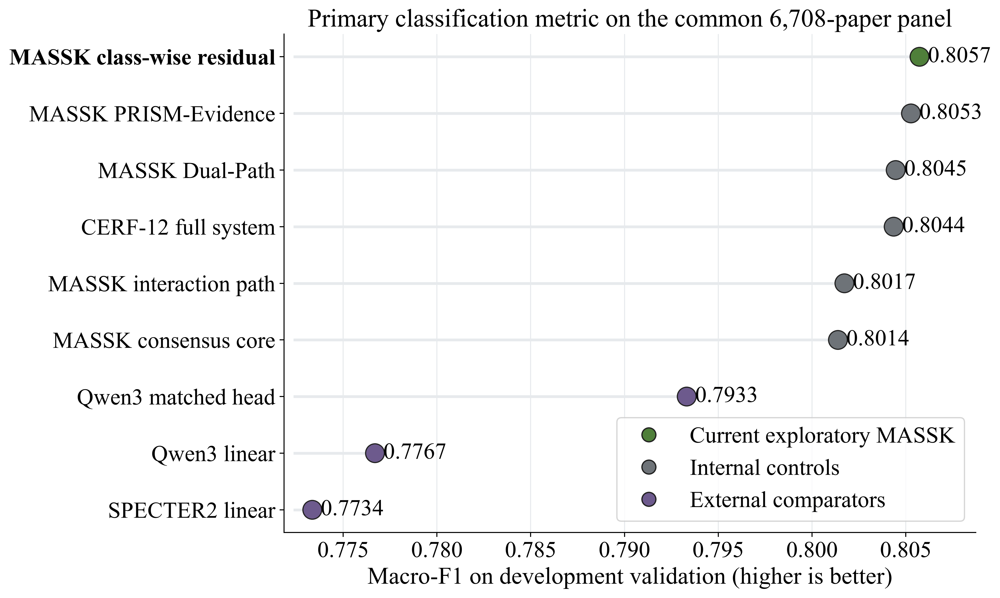

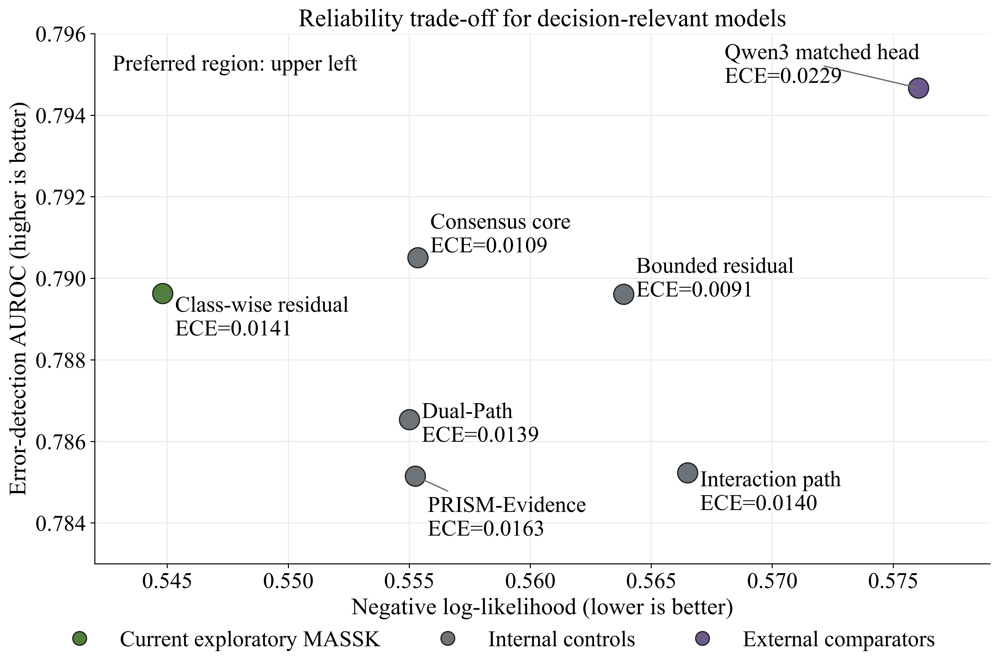

In [11]:
MAIN_TEXT_TRACKS = [
    'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL',
    'MASSK_PRISM_EVIDENCE',
    'MASSK_CERF12_FULL',
    'MASSK_DUAL_PATH',
    'CURRENT_R7_CORE',
    'MASSK_R8_FULL',
    'QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED',
    'QWEN3_0.6B_LINEAR_EXACT',
    'SPECTER2_ADAPTER_LINEAR_EXACT',
]
plot_panel = (
    panel[panel.track.isin(MAIN_TEXT_TRACKS)].copy().sort_values('macro_f1').reset_index(drop=True)
)
assert len(panel) == 19 and set(plot_panel.track) == set(MAIN_TEXT_TRACKS)
display_labels = {
    'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL': 'MASSK class-wise residual',
    'MASSK_PRISM_EVIDENCE': 'MASSK PRISM-Evidence',
    'MASSK_CERF12_FULL': 'CERF-12 full system',
    'MASSK_DUAL_PATH': 'MASSK Dual-Path',
    'CURRENT_R7_CORE': 'MASSK consensus core',
    'MASSK_R8_FULL': 'MASSK interaction path',
    'QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED': 'Qwen3 matched head',
    'QWEN3_0.6B_LINEAR_EXACT': 'Qwen3 linear',
    'SPECTER2_ADAPTER_LINEAR_EXACT': 'SPECTER2 linear',
}
plot_panel['figure_label'] = plot_panel['track'].map(display_labels)
model_colors = {
    track: (
        PALETTE['green']
        if track == EXPLORATORY_VALIDATION_CANDIDATE
        else (
            PALETTE['purple']
            if track
            in {
                'QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED',
                'QWEN3_0.6B_LINEAR_EXACT',
                'SPECTER2_ADAPTER_LINEAR_EXACT',
            }
            else PALETTE['gray']
        )
    )
    for track in MAIN_TEXT_TRACKS
}
positions = np.arange(len(plot_panel))
values = plot_panel['macro_f1'].to_numpy(float)
fig, ax = plt.subplots(figsize=(11.5, 7.4))
ax.hlines(positions, values.min() - 0.001, values, color=PALETTE['light_gray'], linewidth=2.2)
ax.scatter(
    values,
    positions,
    s=220,
    color=[model_colors[t] for t in plot_panel.track],
    edgecolor=PALETTE['black'],
    linewidth=0.9,
    zorder=3,
)
for value, position in zip(values, positions):
    ax.text(value + 0.00045, position, f'{value:.4f}', va='center', fontsize=18)
ax.set_yticks(positions, plot_panel['figure_label'])
for tick, track in zip(ax.get_yticklabels(), plot_panel.track):
    if track == EXPLORATORY_VALIDATION_CANDIDATE:
        tick.set_fontweight('bold')
ax.set_xlim(values.min() - 0.0015, values.max() + 0.0030)
ax.set_xlabel('Macro-F1 on development validation (higher is better)')
ax.set_title('Primary classification metric on the common 6,708-paper panel')
ax.grid(axis='x', color=PALETTE['light_gray'])
category_handles = [
    plt.Line2D(
        [0],
        [0],
        marker='o',
        color='none',
        markerfacecolor=PALETTE['green'],
        markeredgecolor=PALETTE['black'],
        markersize=11,
        label='Current exploratory MASSK',
    ),
    plt.Line2D(
        [0],
        [0],
        marker='o',
        color='none',
        markerfacecolor=PALETTE['gray'],
        markeredgecolor=PALETTE['black'],
        markersize=11,
        label='Internal controls',
    ),
    plt.Line2D(
        [0],
        [0],
        marker='o',
        color='none',
        markerfacecolor=PALETTE['purple'],
        markeredgecolor=PALETTE['black'],
        markersize=11,
        label='External comparators',
    ),
]
ax.legend(handles=category_handles, loc='lower right', frameon=True, facecolor='white')
fig.subplots_adjust(left=0.31, right=0.97, bottom=0.14, top=0.88)
save_figure(fig, 'model_comparison_primary_metrics', 'validation_primary_metric_bar_comparison')

RELIABILITY_TRACKS = [
    'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL',
    'MASSK_PRISM_EVIDENCE',
    'MASSK_DUAL_PATH',
    'CURRENT_R7_CORE',
    'MASSK_R8_FULL',
    'R8_RESIDUAL',
    'QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED',
]
reliability_panel = panel.set_index('track').loc[RELIABILITY_TRACKS].reset_index()
short_labels = {
    'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL': 'Class-wise residual',
    'MASSK_PRISM_EVIDENCE': 'PRISM-Evidence',
    'MASSK_DUAL_PATH': 'Dual-Path',
    'CURRENT_R7_CORE': 'Consensus core',
    'MASSK_R8_FULL': 'Interaction path',
    'R8_RESIDUAL': 'Bounded residual',
    'QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED': 'Qwen3 matched head',
}
offsets = {
    'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL': (10, -20),
    'MASSK_PRISM_EVIDENCE': (10, -34),
    'MASSK_DUAL_PATH': (10, -4),
    'CURRENT_R7_CORE': (10, 18),
    'MASSK_R8_FULL': (10, -16),
    'R8_RESIDUAL': (10, 12),
    'QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED': (-156, 18),
}
fig, ax = plt.subplots(figsize=(11.5, 8.0))
for row in reliability_panel.itertuples(index=False):
    color = (
        PALETTE['green']
        if row.track == EXPLORATORY_VALIDATION_CANDIDATE
        else (
            PALETTE['purple']
            if row.track == 'QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED'
            else PALETTE['gray']
        )
    )
    ax.scatter(
        row.nll,
        row.error_auroc,
        s=260,
        color=color,
        edgecolor=PALETTE['black'],
        linewidth=1,
        zorder=3,
    )
    ax.annotate(
        f"{short_labels[row.track]}\nECE={row.ece_15:.4f}",
        (row.nll, row.error_auroc),
        xytext=offsets[row.track],
        textcoords='offset points',
        fontsize=18,
        ha='left',
        va='center',
        arrowprops={'arrowstyle': '-', 'color': PALETTE['gray'], 'lw': 1.1},
    )
ax.set_xlim(0.542, 0.579)
ax.set_ylim(0.783, 0.796)
ax.set_xlabel('Negative log-likelihood (lower is better)')
ax.set_ylabel('Error-detection AUROC (higher is better)')
ax.set_title('Reliability trade-off for decision-relevant models')
ax.grid(color=PALETTE['light_gray'])
ax.text(0.02, 0.96, 'Preferred region: upper left', transform=ax.transAxes, va='top', fontsize=18)
fig.legend(
    handles=category_handles, loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=3, frameon=False
)
fig.subplots_adjust(left=0.11, right=0.98, bottom=0.16, top=0.90)
save_figure(fig, 'model_comparison_reliability_metrics', 'validation_reliability_tradeoff')

In [12]:
registry = load_csv("results/tables/model_license_revision_inference_registry.csv")
if registry is None:
    registry = pd.DataFrame(columns=["model_id", "license", "revision"])

name_col = first_column(registry, ["model", "model_name", "model_id"])
if name_col is None:
    registry["model"] = MISSING["pending"]
    name_col = "model"

names = registry[name_col].astype(str).str.lower()
is_jina_classification = names.str.contains("jina") & names.str.contains("classification")
is_jina_retrieval = names.str.contains("jina") & names.str.contains("retrieval")
registry["official_model_card"] = np.select(
    [
        names.str.contains("qwen"),
        names.str.contains("specter"),
        names.str.contains("scincl"),
        is_jina_classification,
        is_jina_retrieval,
        names.str.contains("pplx"),
        names.str.contains("modernbert"),
    ],
    [
        "https://huggingface.co/Qwen/Qwen3-Embedding-0.6B",
        "https://huggingface.co/allenai/specter2_classification",
        "https://huggingface.co/malteos/scincl",
        "https://huggingface.co/jinaai/jina-embeddings-v5-text-nano-classification",
        "https://huggingface.co/jinaai/jina-embeddings-v5-text-nano-retrieval",
        "https://huggingface.co/perplexity-ai/pplx-embed-v1-0.6b",
        "https://huggingface.co/answerdotai/ModernBERT-base",
    ],
    default=MISSING["pending"],
)
registry["study_role"] = np.select(
    [
        names.str.contains("qwen|specter"),
        is_jina_classification | names.str.contains("scincl"),
        is_jina_retrieval,
        names.str.contains("modernbert"),
    ],
    [
        "ACTIVE_SEMANTIC_VIEW",
        "MATCHED_LINEAR_COMPARATOR",
        "RETRIEVAL_COMPARATOR",
        "HISTORICAL_NONIDENTICAL_ESTIMAND",
    ],
    default="REGISTERED_COMPARATOR",
)
registry["directly_comparable"] = np.where(
    names.str.contains("modernbert"),
    "NO_NONIDENTICAL_ESTIMAND",
    "YES_WITH_MATCHED_VALIDATION_SCOPE",
)
_, registry = save_table(
    registry,
    "final_model_provenance_registry.csv",
    MISSING["pending"],
)
provenance_view = registry[
    [
        column
        for column in [
            "model_id",
            "revision",
            "license",
            "official_model_card",
            "study_role",
            "directly_comparable",
        ]
        if column in registry
    ]
].copy()
provenance_reader = provenance_view[
    [
        column
        for column in ['model_id', 'revision', 'license', 'study_role']
        if column in provenance_view
    ]
].copy()
if 'revision' in provenance_reader:
    provenance_reader['revision'] = provenance_reader['revision'].astype(str).str.slice(0, 12)
provenance_reader = provenance_reader.rename(
    columns={
        'model_id': 'Model',
        'revision': 'Revision',
        'license': 'License',
        'study_role': 'Role in the study',
    }
)
display(
    provenance_reader.style.hide(axis='index')
    .set_properties(subset=['Model', 'Role in the study'], **{'max-width': '360px', 'white-space': 'normal'})
    .set_caption('Pinned model provenance and analytical role')
)

Model,Revision,License,Role in the study
Qwen/Qwen3-Embedding-0.6B,97b0c614be4d,Apache-2.0,ACTIVE_SEMANTIC_VIEW
allenai/specter2_base,3447645e1def,Apache-2.0,ACTIVE_SEMANTIC_VIEW
jinaai/jina-embeddings-v5-text-nano-classification,a0129e9b8ea4,CC-BY-NC-4.0,MATCHED_LINEAR_COMPARATOR
malteos/scincl,ebc5348d184b,MIT,MATCHED_LINEAR_COMPARATOR
jinaai/jina-embeddings-v5-text-nano-retrieval,ac5d898c8d38,CC-BY-NC-4.0,RETRIEVAL_COMPARATOR
perplexity-ai/pplx-embed-v1-0.6b,2c4d510dd4a7,MIT,REGISTERED_COMPARATOR
answerdotai/ModernBERT-base,8949b909ec90,Apache-2.0,HISTORICAL_NONIDENTICAL_ESTIMAND


## 5. Synchronized ablations and statistical evidence

The full-system m = 6 family and semantic-view m = 2 family are reported together but never conflated. The paired-effect forest is rendered only when the verified gate exposes paired estimates and confidence limits; otherwise the figure is explicitly withheld.


In [13]:
full_gate_eval = load_csv('results/tables/massk_round7_full_system_synchronized_gate.csv')
semantic_gate_eval = load_csv('results/tables/massk_round7_semantic_view_deletion_gate.csv')
dual_gate = pd.read_csv(TABLES / 'massk_dual_path_statistical_gate.csv', keep_default_na=False)
cs3r_gate = pd.read_csv(TABLES / 'massk_cs3r_ablation_deltas.csv', keep_default_na=False)
r9_gate = pd.read_csv(TABLES / 'massk_round9_statistical_gate.csv', keep_default_na=False)
r10_gate = pd.read_csv(TABLES / 'massk_round10_statistical_gate.csv', keep_default_na=False)
r11_comparison = pd.read_csv(
    TABLES / "massk_round11_uncertainty_comparison.csv",
    keep_default_na=False,
)
r11_gate = pd.read_csv(
    TABLES / "massk_round11_uncertainty_ablation_gate.csv",
    keep_default_na=False,
)
r11_fit = pd.read_csv(
    TABLES / "massk_round11_uncertainty_fit_audit.csv",
    keep_default_na=False,
)
r12_gate = pd.read_csv(TABLES / "massk_round12_synchronized_gate.csv", keep_default_na=False)
ablation_parts = []
dual_gate_labeled = dual_gate.copy()
dual_gate_labeled['comparison_role'] = dual_gate_labeled.control.map(
    {
        'CURRENT_R7_CORE': 'INTERNAL_CONSENSUS_PATH_CONTROL',
        'MASSK_R8_FULL': 'INTERNAL_INTERACTION_PATH_CONTROL',
        'R8_QWEN': 'SINGLE_VIEW_CONTROL_NOT_PURE_DELETION',
        'R8_SPECTER': 'SINGLE_VIEW_CONTROL_NOT_PURE_DELETION',
    }
)
for family, frame, expected in [
    ('ROUND14_CLASSWISE_RETRIEVAL_CLASSIFICATION_M1', r14_gate, 1),
    ('CERF12_FULL_SYSTEM_NEGATIVE_M6', r12_gate, 6),
    ('R11_UNCERTAINTY_NEGATIVE_M2', r11_gate, 2),
    ('PRISM_EVIDENCE_PRUNED_M4', prism_gate, 4),
    ('PRISM_FULL_M7', r10_gate, 7),
    ('R9_CEDR_NEGATIVE_M5', r9_gate, 5),
    ('DUAL_PATH_CONDITIONAL_M4', dual_gate_labeled, 4),
    ('CS3R_DIAGNOSTIC', cs3r_gate, 5),
    ('ROUND7_FULL_SYSTEM_M6', full_gate_eval, 6),
    ('ROUND7_SEMANTIC_VIEW_M2', semantic_gate_eval, 2),
]:
    if frame is not None:
        part = frame.copy()
        part.insert(0, 'ablation_family', family)
        part['expected_control_count'] = expected
        part['observed_control_count'] = len(frame)
        part['family_complete'] = len(frame) == expected
        ablation_parts.append(part)
final_ablation = pd.concat(ablation_parts, ignore_index=True, sort=False)
_, final_ablation = save_table(final_ablation, 'final_ablation_summary.csv', MISSING['applicable'])
ablation_inventory = []
for part in ablation_parts:
    family = str(part.ablation_family.iloc[0])
    filename = 'ablation_' + family.lower() + '.csv'
    _, compact_part = save_table(part, filename, MISSING['applicable'])
    ablation_inventory.append(
        {
            'family': family,
            'artifact': filename,
            'rows': len(compact_part),
            'columns': len(compact_part.columns),
        }
    )
ablation_index = pd.DataFrame(ablation_inventory)
_, ablation_index = save_table(ablation_index, 'final_ablation_family_index.csv')
final_statistics = r14_gate.copy()
final_statistics['comparison'] = (
    final_statistics['candidate'].astype(str) + ' − ' + final_statistics['control'].astype(str)
)
final_statistics['scope'] = 'CLASSWISE_RETRIEVAL_POST_SELECTION_DEVELOPMENT_VALIDATION'
final_statistics['authority_status'] = (
    'CLASSIFICATION_GATE_FAILED_NOMINAL_POST_HOC_RELIABILITY_INTERVALS'
)
final_statistics['selection_adjusted_inference'] = False
_, final_statistics = save_table(
    final_statistics, 'final_statistical_tests.csv', MISSING['applicable']
)
r9_comparison = pd.read_csv(TABLES / 'massk_round9_model_comparison.csv', keep_default_na=False)
r10_comparison = pd.read_csv(TABLES / 'massk_round10_model_comparison.csv', keep_default_na=False)
refinement_ledger = pd.DataFrame(
    [
        {
            'configuration': 'Cross-view interaction',
            'endpoint': 'Macro-F1',
            'score': float(round8_raw.query("model == 'MASSK_R8_FULL'").macro_f1.iloc[0]),
            'decision': 'NOT_SELECTED',
        },
        {
            'configuration': 'Dual consensus–interaction',
            'endpoint': 'Macro-F1',
            'score': float(dual_raw.query("model == 'MASSK_DUAL_PATH'").macro_f1.iloc[0]),
            'decision': 'EXPLORATORY_UNCONFIRMED',
        },
        {
            'configuration': 'CEDR disagreement router',
            'endpoint': 'Macro-F1',
            'score': float(r9_comparison.query("model == 'MASSK_R9_CEDR_FULL'").macro_f1.iloc[0]),
            'decision': 'REJECTED',
        },
        {
            'configuration': 'Full PRISM',
            'endpoint': 'Macro-F1',
            'score': float(
                r10_comparison.query("model == 'MASSK_R10_PRISM_FULL'").macro_f1.iloc[0]
            ),
            'decision': 'REJECTED_THEN_PRUNED',
        },
        {
            'configuration': 'PRISM-Evidence',
            'endpoint': 'Macro-F1',
            'score': float(prism.macro_f1),
            'decision': 'PRIOR_POINT_LEADER_NOT_CONFIRMED',
        },
        {
            'configuration': 'Class-wise retrieval residual',
            'endpoint': 'Macro-F1',
            'score': float(candidate.macro_f1),
            'decision': 'POINT_LEADER_CLASSIFICATION_GATE_FAILED_NOMINAL_POST_HOC_RELIABILITY_SIGNAL',
        },
        {
            'configuration': 'DURH uncertainty head',
            'endpoint': 'Error-AUROC',
            'score': float(r11_comparison.iloc[0].error_auroc),
            'decision': 'REJECTED_0_OF_6_ACTIVE',
        },
        {
            'configuration': 'Full four-branch CERF-12',
            'endpoint': 'Macro-F1',
            'score': float(r12_raw.query("model == 'MASSK_CERF12_FULL'").macro_f1.iloc[0]),
            'decision': 'REJECTED_2_OF_6_GATES',
        },
    ]
)
_, refinement_ledger = save_table(refinement_ledger, 'massk_refinement_decision_ledger.csv')
decision_labels = {
    'NOT_SELECTED': 'Not selected',
    'EXPLORATORY_UNCONFIRMED': 'Exploratory; not confirmed',
    'REJECTED': 'Rejected by the development criterion',
    'REJECTED_THEN_PRUNED': 'Rejected, then simplified',
    'PRIOR_POINT_LEADER_NOT_CONFIRMED': 'Earlier point leader; not confirmed',
    'POINT_LEADER_CLASSIFICATION_GATE_FAILED_NOMINAL_POST_HOC_RELIABILITY_SIGNAL': (
        'Current point leader; classification gate not met'
    ),
    'REJECTED_0_OF_6_ACTIVE': 'Rejected; no active outer context',
    'REJECTED_2_OF_6_GATES': 'Rejected; two of six gates met',
}
refinement_reader = refinement_ledger.copy()
refinement_reader['decision'] = refinement_reader['decision'].map(decision_labels)
display(
    refinement_reader.round(6).style.hide(axis='index')
    .set_properties(subset=['configuration', 'decision'], **{'max-width': '420px', 'white-space': 'normal'})
    .set_caption('Development-stage refinement decisions')
)

configuration,endpoint,score,decision
Cross-view interaction,Macro-F1,0.801727,Not selected
Dual consensus–interaction,Macro-F1,0.804461,Exploratory; not confirmed
CEDR disagreement router,Macro-F1,0.800553,Rejected by the development criterion
Full PRISM,Macro-F1,0.804471,"Rejected, then simplified"
PRISM-Evidence,Macro-F1,0.805275,Earlier point leader; not confirmed
Class-wise retrieval residual,Macro-F1,0.805731,Current point leader; classification gate not met
DURH uncertainty head,Error-AUROC,0.785151,Rejected; no active outer context
Full four-branch CERF-12,Macro-F1,0.804353,Rejected; two of six gates met


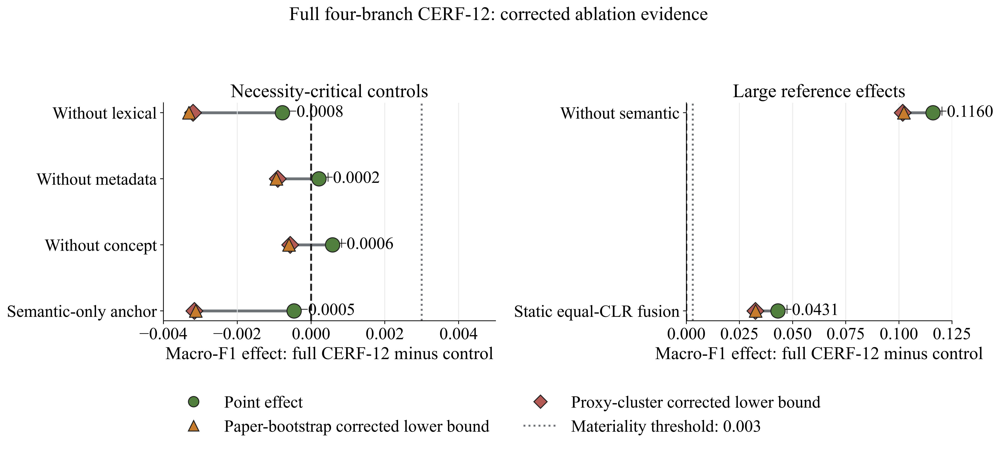

In [14]:
forest = r12_gate.copy()
labels = {
    'CERF12_MINUS_LEXICAL': 'Without lexical',
    'CERF12_MINUS_METADATA': 'Without metadata',
    'CERF12_MINUS_CONCEPT': 'Without concept',
    'CERF12_SEMANTIC_ONLY': 'Semantic-only anchor',
    'CERF12_MINUS_SEMANTIC': 'Without semantic',
    'CERF12_STATIC_EQUAL_CLR': 'Static equal-CLR fusion',
}
panels = [
    (
        'Necessity-critical controls',
        [
            'CERF12_MINUS_LEXICAL',
            'CERF12_MINUS_METADATA',
            'CERF12_MINUS_CONCEPT',
            'CERF12_SEMANTIC_ONLY',
        ],
        (-0.0040, 0.0050),
        0.00012,
    ),
    (
        'Large reference effects',
        ['CERF12_MINUS_SEMANTIC', 'CERF12_STATIC_EQUAL_CLR'],
        (0, 0.125),
        0.0020,
    ),
]
fig, axes = plt.subplots(1, 2, figsize=(15.0, 6.8), gridspec_kw={'width_ratios': [1.25, 1]})
for ax, (title, controls, xlim, offset) in zip(axes, panels):
    part = forest.set_index('control').loc[controls].reset_index()
    positions = np.arange(len(part))[::-1]
    point = part.delta_macro_f1.to_numpy(float)
    paper_lcb = part.paper_bonferroni_lcb.to_numpy(float)
    cluster_lcb = part.proxy_cluster_bonferroni_lcb.to_numpy(float)
    lower = np.minimum(paper_lcb, cluster_lcb)
    ax.hlines(positions, lower, point, color=PALETTE['gray'], linewidth=3, zorder=1)
    ax.scatter(
        point,
        positions,
        s=230,
        marker='o',
        color=PALETTE['green'],
        edgecolor=PALETTE['black'],
        zorder=4,
    )
    ax.scatter(
        paper_lcb,
        positions,
        s=180,
        marker='^',
        color=PALETTE['orange'],
        edgecolor=PALETTE['black'],
        zorder=3,
    )
    ax.scatter(
        cluster_lcb,
        positions,
        s=160,
        marker='D',
        color=PALETTE['red'],
        edgecolor=PALETTE['black'],
        zorder=2,
    )
    for x, y in zip(point, positions):
        ax.text(x + offset, y, f'{x:+.4f}'.replace('-', '−'), va='center', fontsize=18)
    ax.set_yticks(positions, part.control.map(labels).fillna(part.control))
    ax.axvline(0, color=PALETTE['black'], ls='--', lw=2)
    ax.axvline(0.003, color=PALETTE['gray'], ls=':', lw=2)
    ax.set_xlim(*xlim)
    ax.set_title(title)
    ax.grid(axis='x', color=PALETTE['light_gray'])
    ax.set_xlabel('Macro-F1 effect: full CERF-12 minus control')
fig.suptitle('Full four-branch CERF-12: corrected ablation evidence', y=0.97)
handles = [
    plt.Line2D(
        [0],
        [0],
        marker='o',
        color='none',
        markerfacecolor=PALETTE['green'],
        markeredgecolor=PALETTE['black'],
        markersize=11,
        label='Point effect',
    ),
    plt.Line2D(
        [0],
        [0],
        marker='^',
        color='none',
        markerfacecolor=PALETTE['orange'],
        markeredgecolor=PALETTE['black'],
        markersize=11,
        label='Paper-bootstrap corrected lower bound',
    ),
    plt.Line2D(
        [0],
        [0],
        marker='D',
        color='none',
        markerfacecolor=PALETTE['red'],
        markeredgecolor=PALETTE['black'],
        markersize=10,
        label='Proxy-cluster corrected lower bound',
    ),
    plt.Line2D([0], [0], color=PALETTE['gray'], ls=':', lw=2, label='Materiality threshold: 0.003'),
]
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0.16, 1, 0.92))
save_figure(fig, 'ablation_performance', 'cerf12_full_system_corrected_lcb_forest')

## 6. Calibration and uncertainty: class-wise retrieval residual versus the receipt-backed core

The table reports distinct outer paper-level estimands; the plot uses PRISM-Evidence validation predictions.

In [15]:
def choose_prediction_view(frame, reporting_model):
    if frame is None or frame.empty:
        return None, MISSING['executed']
    model_col = first_column(frame, ['model', 'track', 'configuration', 'variant'])
    if model_col is None:
        return frame.copy(), 'SINGLE_MODEL_ARTIFACT'
    labels = frame[model_col].astype(str)
    exact = labels.str.upper().eq(reporting_model.upper())
    if not exact.any() and reporting_model == 'SEMANTIC_ONLY':
        exact = labels.str.upper().str.contains('SEMANTIC') & labels.str.upper().str.contains(
            'ONLY'
        )
    if not exact.any():
        return None, MISSING['executed']
    selected = labels[exact].value_counts().index[0]
    return frame[labels.eq(selected)].copy(), str(selected)


core_reporting_predictions, core_prediction_label = choose_prediction_view(
    predictions, REPORTING_MODEL
)
candidate_predictions = round14_paper.copy()
analysis_predictions = candidate_predictions
PREDICTION_MODEL = EXPLORATORY_VALIDATION_CANDIDATE
PREDICTION_ROLE = 'MULTIOBJECTIVE_EXPLORATORY_CANDIDATE_CLASSIFICATION_GATE_FAILED_NOMINAL_POST_HOC_RELIABILITY_SIGNAL'
prediction_columns = pd.DataFrame(
    [
        {
            'model': PREDICTION_MODEL,
            'artifact_label': PREDICTION_MODEL,
            'rows': len(candidate_predictions),
            'scope': 'DEVELOPMENT_VALIDATION_ONLY',
            'role': PREDICTION_ROLE,
            'status': 'READY',
        },
        {
            'model': REPORTING_MODEL,
            'artifact_label': core_prediction_label,
            'rows': 0 if core_reporting_predictions is None else len(core_reporting_predictions),
            'scope': 'ROUND7_RECEIPT_BACKED',
            'role': 'REPORTING_MODEL',
            'status': 'READY',
        },
    ]
)
prediction_reader = prediction_columns[['model', 'rows', 'scope', 'status']].copy()
prediction_reader['scope'] = prediction_reader['scope'].replace(
    {
        'DEVELOPMENT_VALIDATION_ONLY': 'Development validation only',
        'ROUND7_RECEIPT_BACKED': 'Receipt-backed Round 7 reference',
    }
)
display(
    prediction_reader.style.hide(axis='index')
    .format({'rows': '{:,.0f}'})
    .set_caption('Prediction artifacts used in the development analysis')
)

model,rows,scope,status
MASSK_CLASSWISE_RETRIEVAL_RESIDUAL,"6,708",Development validation only,READY
SEMANTIC_ONLY,"6,708",Receipt-backed Round 7 reference,READY


In [16]:
calibration_rows = []
for model in [EXPLORATORY_VALIDATION_CANDIDATE, 'CURRENT_R7_CORE']:
    row = final_model[final_model.model.eq(model)].iloc[0]
    method = (
        'class-wise semantic-neighbour residual fitted inside each outer-train context'
        if model == EXPLORATORY_VALIDATION_CANDIDATE
        else 'identity after calibrated semantic consensus'
    )
    calibration_rows.append(
        {
            'evidence_level': 'OUTER_PAPER_LEVEL',
            'model': model,
            'selected_method': method,
            'uncertainty_method': 'one_minus_top_two_probability_margin_for_error_auroc_and_aurc',
            'selection_units': int(row.unique_papers),
            'nll': row.nll,
            'ece_15': row.ece_15,
            'brier_multiclass': row.brier_multiclass,
            'error_auroc': row.error_auroc,
            'aurc': row.aurc,
        }
    )
if calibration_raw is not None:
    selected_calibration, _ = choose_prediction_view(calibration_raw, REPORTING_MODEL)
    selected_calibration = (
        calibration_raw.copy() if selected_calibration is None else selected_calibration
    )
    calibration_rows.append(
        {
            'evidence_level': 'INNER_CALIBRATION_SELECTION',
            'model': REPORTING_MODEL,
            'selected_method': ' | '.join(
                sorted(selected_calibration.selected_method.astype(str).unique())
            ),
            'uncertainty_method': ' | '.join(
                sorted(selected_calibration.uncertainty_method.astype(str).unique())
            ),
            'selection_units': len(selected_calibration),
            'nll': pd.to_numeric(selected_calibration.raw_nll, errors='coerce').mean(),
            'brier_multiclass': pd.to_numeric(
                selected_calibration.raw_brier, errors='coerce'
            ).mean(),
            'error_auroc': pd.to_numeric(
                selected_calibration.uncertainty_error_auroc_inner, errors='coerce'
            ).mean(),
        }
    )
final_calibration = pd.DataFrame(calibration_rows)
final_calibration['scope'] = 'EXPLORATORY_POST_SELECTION_DEVELOPMENT_VALIDATION'
final_calibration['authority_status'] = (
    final_calibration['model']
    .map(
        {
            EXPLORATORY_VALIDATION_CANDIDATE: 'MULTIOBJECTIVE_EXPLORATORY_CANDIDATE_CLASSIFICATION_GATE_FAILED_NOMINAL_POST_HOC_RELIABILITY_SIGNAL',
            'CURRENT_R7_CORE': 'ROUND7_RECEIPT_BACKED_REPORTING_MODEL',
            REPORTING_MODEL: 'ROUND7_RECEIPT_BACKED_REPORTING_MODEL',
        }
    )
    .fillna('INNER_SELECTION_DIAGNOSTIC')
)
_, final_calibration = save_table(
    final_calibration, 'final_calibration_uncertainty_summary.csv', MISSING['executed']
)
calibration_reader = final_calibration[
    [
        'model',
        'selection_units',
        'nll',
        'ece_15',
        'brier_multiclass',
        'error_auroc',
        'aurc',
    ]
].copy()
calibration_numeric_columns = [
    'selection_units',
    'nll',
    'ece_15',
    'brier_multiclass',
    'error_auroc',
    'aurc',
]
calibration_reader[calibration_numeric_columns] = calibration_reader[
    calibration_numeric_columns
].apply(pd.to_numeric, errors='coerce')
display(
    calibration_reader.style.hide(axis='index')
    .format(
        {
            'selection_units': '{:,.0f}',
            'nll': '{:.4f}',
            'ece_15': '{:.4f}',
            'brier_multiclass': '{:.4f}',
            'error_auroc': '{:.4f}',
            'aurc': '{:.4f}',
        },
        na_rep='—',
    )
    .set_caption('Calibration and uncertainty results by evaluated model')
)


def confidence_error_view(frame):
    if frame is None or frame.empty:
        return None
    true_col = first_column(frame, ['y_true', 'true_label', 'label_id', 'target'])
    probability_columns = sorted(
        [column for column in frame if re.fullmatch(r'probability_\d+', str(column))],
        key=lambda column: int(str(column).rsplit('_', 1)[1]),
    )
    if true_col is None or not probability_columns:
        return None
    probability = frame[probability_columns].apply(pd.to_numeric, errors='coerce').to_numpy()
    truth = pd.to_numeric(frame[true_col], errors='coerce').to_numpy()
    valid = np.isfinite(probability).all(1) & np.isfinite(truth)
    probability = probability[valid]
    truth = truth[valid].astype(int)
    clipped = np.clip(probability, 1e-12, 1)
    ordered = np.sort(probability, axis=1)
    confidence = probability.max(1)
    return pd.DataFrame(
        {
            'correct': probability.argmax(1) == truth,
            'confidence': confidence,
            'one_minus_confidence': 1 - confidence,
            'margin_uncertainty': 1 - (ordered[:, -1] - ordered[:, -2]),
            'entropy_uncertainty': -(clipped * np.log(clipped)).sum(1) / np.log(clipped.shape[1]),
        }
    )


risk_view = confidence_error_view(analysis_predictions)
if risk_view is None or risk_view.empty:
    reliability = pd.DataFrame()
else:
    risk_view['confidence_bin'] = pd.cut(
        risk_view.confidence.clip(0, 1), np.linspace(0, 1, 11), include_lowest=True
    )
    reliability = (
        risk_view.groupby('confidence_bin', observed=True)
        .agg(
            mean_confidence=('confidence', 'mean'),
            empirical_accuracy=('correct', 'mean'),
            papers=('correct', 'size'),
        )
        .reset_index()
    )
show_table(
    reliability
    if not reliability.empty
    else pd.DataFrame([{'calibration_bins': MISSING['executed'], 'status': 'NOT_EXECUTED'}])
)

model,selection_units,nll,ece_15,brier_multiclass,error_auroc,aurc
MASSK_CLASSWISE_RETRIEVAL_RESIDUAL,"6,708",0.5448,0.0141,0.2789,0.7896,0.0705
CURRENT_R7_CORE,"6,708",0.5554,0.0109,0.2834,0.7905,0.0723
SEMANTIC_ONLY,6,0.5876,—,0.2986,0.7728,—


,confidence_bin,mean_confidence,empirical_accuracy,papers
0,"(0.2, 0.3]",0.284724,0.750000,4
1,"(0.3, 0.4]",0.365610,0.407407,81
2,"(0.4, 0.5]",0.464015,0.523973,292
3,"(0.5, 0.6]",0.552343,0.528131,551
4,"(0.6, 0.7]",0.651133,0.613487,608
5,"(0.7, 0.8]",0.754328,0.722283,911
6,"(0.8, 0.9]",0.854530,0.852123,1366
7,"(0.9, 1.0]",0.951426,0.952677,2895


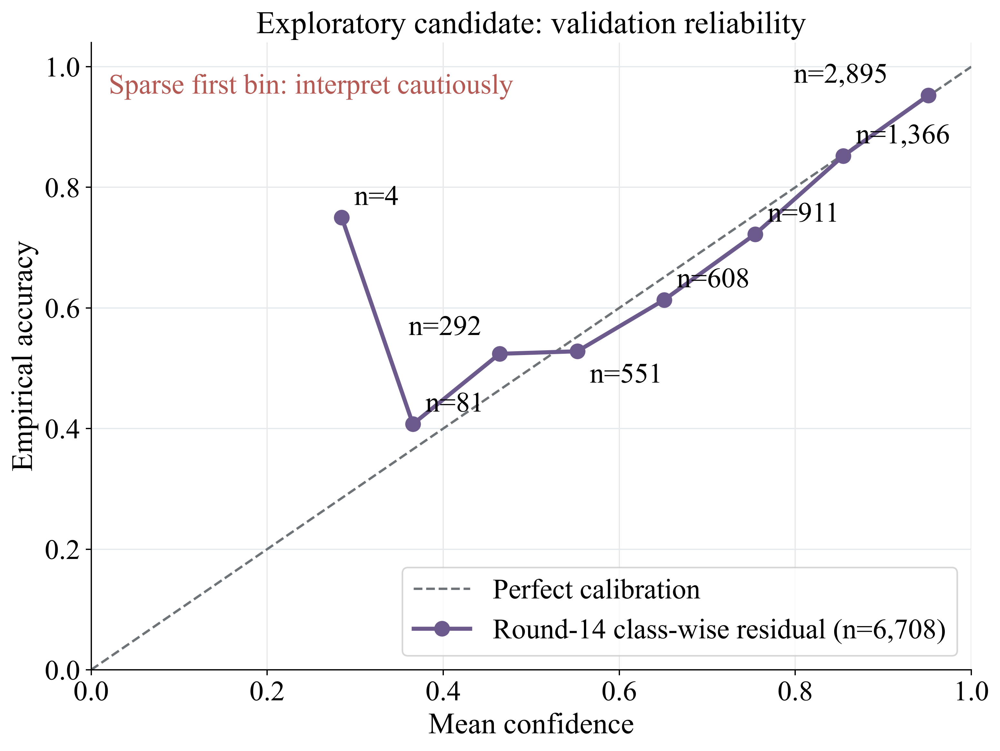

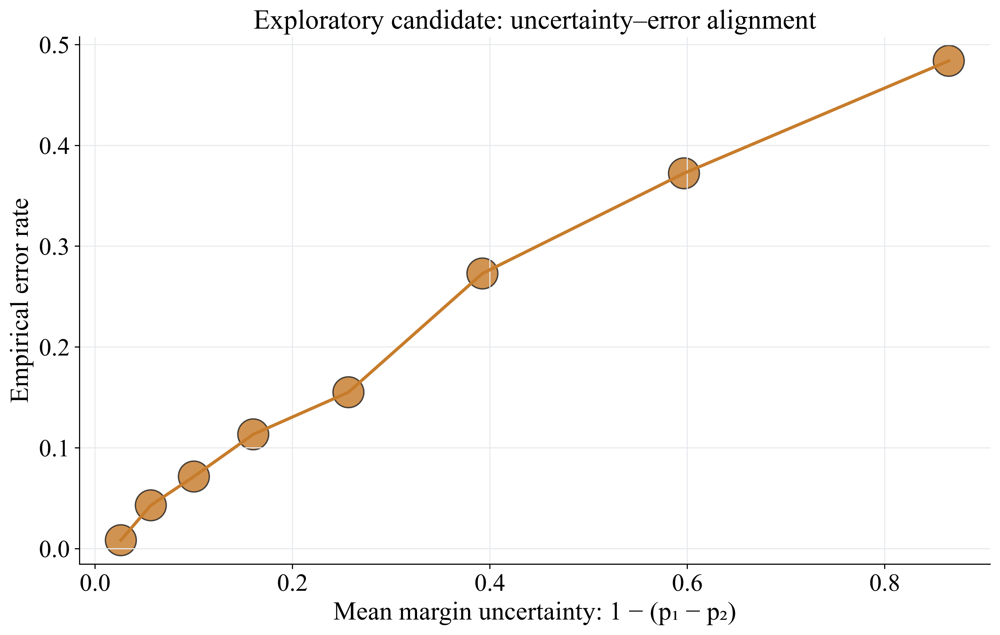

In [17]:
if reliability.empty:
    withhold_figure(
        'calibration_reliability',
        'calibration_reliability',
        MISSING['executed'],
        'Reporting-model confidence and correctness are unavailable',
    )
else:
    fig, ax = plt.subplots(figsize=(9.2, 7.0))
    ax.plot([0, 1], [0, 1], linestyle='--', color=PALETTE['gray'], label='Perfect calibration')
    ax.plot(
        reliability['mean_confidence'],
        reliability['empirical_accuracy'],
        marker='o',
        markersize=9,
        linewidth=2.6,
        color=PALETTE['purple'],
        label='Round-14 class-wise residual (n=6,708)',
    )
    if 'papers' in reliability.columns:
        annotation_offsets = [(8, 8), (8, 8), (-58, 12), (8, -20), (8, 8), (8, 8), (8, 8), (-86, 8)]
        for row, offset in zip(reliability.itertuples(index=False), annotation_offsets):
            ax.annotate(
                f'n={int(row.papers):,}',
                (row.mean_confidence, row.empirical_accuracy),
                xytext=offset,
                textcoords='offset points',
                fontsize=18,
            )
        if int(reliability.iloc[0]['papers']) < 20:
            ax.text(
                0.02,
                0.95,
                'Sparse first bin: interpret cautiously',
                transform=ax.transAxes,
                color=PALETTE['red'],
                fontsize=18,
                va='top',
            )
    ax.set_xlabel('Mean confidence')
    ax.set_ylabel('Empirical accuracy')
    ax.set_title('Exploratory candidate: validation reliability')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.04)
    ax.grid(color=PALETTE['light_gray'])
    ax.legend(loc='lower right', frameon=True, facecolor='white')
    fig.tight_layout()
    save_figure(fig, 'calibration_reliability', 'calibration_reliability')

if risk_view is None or risk_view.empty or risk_view['margin_uncertainty'].nunique() < 2:
    withhold_figure(
        'uncertainty_vs_error',
        'uncertainty_vs_error',
        MISSING['measured'],
        'Auditable uncertainty variation is unavailable',
    )
else:
    quantiles = min(8, int(risk_view['margin_uncertainty'].nunique()))
    risk_view['uncertainty_bin'] = pd.qcut(
        risk_view['margin_uncertainty'], q=quantiles, duplicates='drop'
    )
    selective = (
        risk_view.groupby('uncertainty_bin', observed=True)
        .agg(
            mean_uncertainty=('margin_uncertainty', 'mean'),
            error_rate=('correct', lambda x: 1 - x.mean()),
            papers=('correct', 'size'),
        )
        .reset_index()
    )
    fig, ax = plt.subplots(figsize=(10.5, 6.8))
    sizes = 90 + 420 * selective['papers'] / selective['papers'].max()
    ax.scatter(
        selective['mean_uncertainty'],
        selective['error_rate'],
        s=sizes,
        color=PALETTE['orange'],
        edgecolor=PALETTE['black'],
        alpha=0.82,
    )
    ax.plot(
        selective['mean_uncertainty'],
        selective['error_rate'],
        color=PALETTE['orange'],
        linewidth=2.3,
    )
    ax.set_xlabel('Mean margin uncertainty: 1 − (p₁ − p₂)')
    ax.set_ylabel('Empirical error rate')
    ax.set_title('Exploratory candidate: uncertainty–error alignment')
    ax.grid(color=PALETTE['light_gray'])
    fig.tight_layout()
    save_figure(fig, 'uncertainty_vs_error', 'uncertainty_vs_error')

## 7. Retrieval and closed-vocabulary concept tagging

Structural metrics retain their evaluation scope and aggregation unit. Retrieval and tagging are displayed on separate canvases because they answer different scientific questions.


In [18]:
def structural_family(frame, family, keywords):
    if frame is None or frame.empty:
        return pd.DataFrame(columns=['model', 'metric', 'value', 'task', 'scope'])
    task_col = first_column(frame, ['task', 'evaluation_task', 'metric_family'])
    metric_col = first_column(frame, ['metric', 'metric_name'])
    value_col = first_column(frame, ['value', 'score', 'metric_value'])
    model_col = first_column(frame, ['model', 'track', 'configuration', 'variant'])
    selected = frame.copy()
    if task_col:
        mask = selected[task_col].astype(str).str.lower().str.contains('|'.join(keywords))
        selected = selected[mask]
    if metric_col and value_col:
        out = pd.DataFrame(
            {
                'model': selected[model_col].astype(str) if model_col else REPORTING_MODEL,
                'metric': selected[metric_col].astype(str),
                'value': pd.to_numeric(selected[value_col], errors='coerce'),
            }
        )
        out = out[out['metric'].str.lower().str.contains('|'.join(keywords))]
    else:
        value_columns = [
            column
            for column in selected.columns
            if any(key in str(column).lower() for key in keywords)
        ]
        identifiers = [model_col] if model_col else []
        out = (
            selected.melt(
                id_vars=identifiers, value_vars=value_columns, var_name='metric', value_name='value'
            )
            if value_columns
            else pd.DataFrame(columns=['model', 'metric', 'value'])
        )
        if not out.empty:
            out['model'] = out[model_col].astype(str) if model_col else REPORTING_MODEL
            out['value'] = pd.to_numeric(out['value'], errors='coerce')
            out = out[['model', 'metric', 'value']]
    if not out.empty:
        out = out.dropna(subset=['value'])
        out['task'] = family
        out['scope'] = 'EXPLORATORY_POST_SELECTION_DEVELOPMENT_VALIDATION'
    return out


retrieval_view = structural_family(
    structural_raw,
    'SEMANTIC_RETRIEVAL',
    ['retrieval', 'ndcg_at', 'mrr_at', 'map_at', 'recall_at', 'precision_at'],
)
keyphrase_view = structural_family(
    structural_raw,
    'CLOSED_VOCABULARY_TAGGING',
    ['keyphrase', 'concept', 'tagging', 'present_f1', 'absent_f1'],
)


def aggregate_structural(view):
    if view.empty:
        return view
    out = view.groupby(['model', 'metric', 'task', 'scope'], as_index=False).agg(
        value_mean=('value', 'mean'), value_sd=('value', 'std'), validation_units=('value', 'size')
    )
    out['model'] = out['model'].replace(
        {
            'MASSK fixed score consensus': 'MASSK-CORE dual-view score consensus',
            'MASSK fixed tagging consensus': 'MASSK-CORE dual-view tagging consensus',
        }
    )
    out['reporting_role'] = np.where(
        out['model'].str.startswith('MASSK-CORE'), 'PROPOSED_STRUCTURAL_SYSTEM', 'COMPARATOR'
    )
    out['provenance_tier'] = 'SUPPLEMENTAL_DESCRIPTIVE_NOT_RECEIPT_BACKED'
    return out


fallback = lambda task: pd.DataFrame(
    [
        {
            'model': REPORTING_MODEL,
            'metric': MISSING['executed'],
            'value': MISSING['executed'],
            'task': task,
            'scope': 'EXPLORATORY_POST_SELECTION_DEVELOPMENT_VALIDATION',
            'status': SYNTHESIS_STATUS,
        }
    ]
)
_, final_retrieval = save_table(
    (
        aggregate_structural(retrieval_view)
        if not retrieval_view.empty
        else fallback('SEMANTIC_RETRIEVAL')
    ),
    'final_retrieval_comparison.csv',
    MISSING['applicable'],
)
_, final_keyphrase = save_table(
    (
        aggregate_structural(keyphrase_view)
        if not keyphrase_view.empty
        else fallback('CLOSED_VOCABULARY_TAGGING')
    ),
    'final_keyphrase_comparison.csv',
    MISSING['applicable'],
)
retrieval_metric = final_retrieval[final_retrieval['metric'].eq('ndcg_at_10')].copy()
retrieval_metric['numeric_value'] = pd.to_numeric(retrieval_metric['value_mean'], errors='coerce')
retrieval_leader = retrieval_metric.sort_values('numeric_value', ascending=False).iloc[0]
keyphrase_metric = final_keyphrase[final_keyphrase['metric'].eq('keyphrase_f1_at_10')].copy()
keyphrase_metric['numeric_value'] = pd.to_numeric(keyphrase_metric['value_mean'], errors='coerce')
keyphrase_leader = keyphrase_metric.sort_values('numeric_value', ascending=False).iloc[0]
endpoint_leaders = pd.DataFrame(
    [
        {
            'endpoint': 'Classification validation leader',
            'metric': 'Macro-F1 ↑',
            'leader': 'MASSK class-wise retrieval residual',
            'value': panel.loc[
                panel['track'].eq('MASSK_CLASSWISE_RETRIEVAL_RESIDUAL'), 'macro_f1'
            ].iloc[0],
            'interpretation': 'Exploratory point leader; classification gate failed; nominal post-hoc reliability signal observed',
        },
        {
            'endpoint': 'Receipt-backed classification reference',
            'metric': 'Macro-F1 ↑',
            'leader': 'Consensus path / MASSK core',
            'value': panel.loc[panel['track'].eq('CURRENT_R7_CORE'), 'macro_f1'].iloc[0],
            'interpretation': 'Round-7 receipt-backed internal reference',
        },
        {
            'endpoint': 'Semantic retrieval',
            'metric': 'nDCG@10 ↑',
            'leader': retrieval_leader['model'],
            'value': retrieval_leader['numeric_value'],
            'interpretation': 'Supplemental proxy-relevance endpoint',
        },
        {
            'endpoint': 'Closed-vocabulary concept tagging',
            'metric': 'F1@10 ↑',
            'leader': keyphrase_leader['model'],
            'value': keyphrase_leader['numeric_value'],
            'interpretation': 'Comparator leads; no MASSK superiority claim',
        },
        {
            'endpoint': 'Probability calibration',
            'metric': 'ECE-15 ↓',
            'leader': 'MASSK semantic core',
            'value': panel.loc[panel['track'].eq('CURRENT_R7_CORE'), 'ece_15'].iloc[0],
            'interpretation': 'Receipt-backed semantic-core ECE reference (not the panel minimum)',
        },
    ]
)
_, endpoint_leaders = save_table(endpoint_leaders, 'endpoint_leader_summary.csv')
show_table(endpoint_leaders.round({'value': 4}), rows=len(endpoint_leaders))

,endpoint,metric,leader,value,interpretation
0,Classification validation leader,Macro-F1 ↑,MASSK class-wise retrieval residual,0.8057,Exploratory point leader; classification gate failed; nominal post-hoc reliability sig...
1,Receipt-backed classification reference,Macro-F1 ↑,Consensus path / MASSK core,0.8014,Round-7 receipt-backed internal reference
2,Semantic retrieval,nDCG@10 ↑,MASSK-CORE dual-view score consensus,0.7807,Supplemental proxy-relevance endpoint
3,Closed-vocabulary concept tagging,F1@10 ↑,Qwen3 raw-embedding GPU linear OVR,0.3324,Comparator leads; no MASSK superiority claim
4,Probability calibration,ECE-15 ↓,MASSK semantic core,0.0109,Receipt-backed semantic-core ECE reference (not the panel minimum)


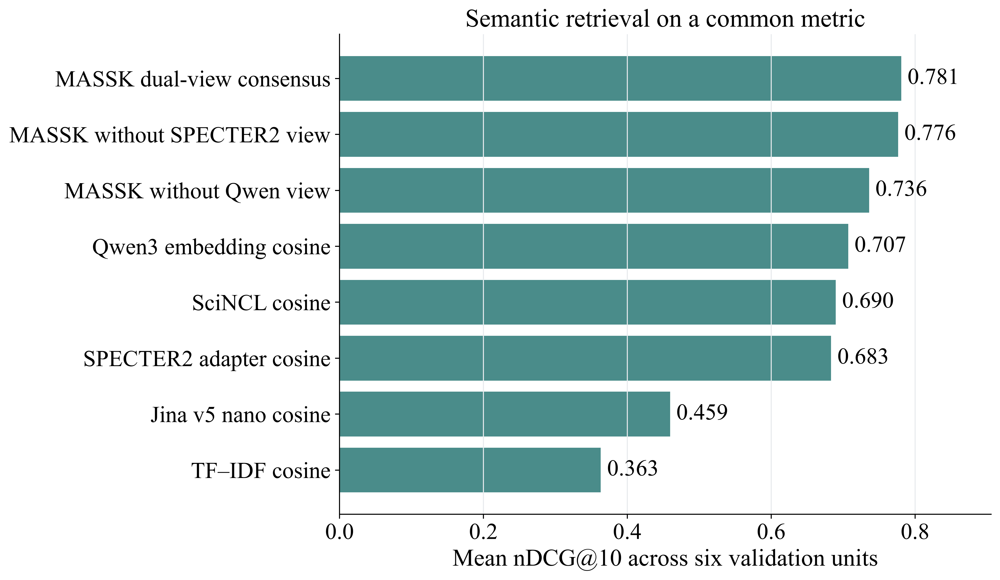

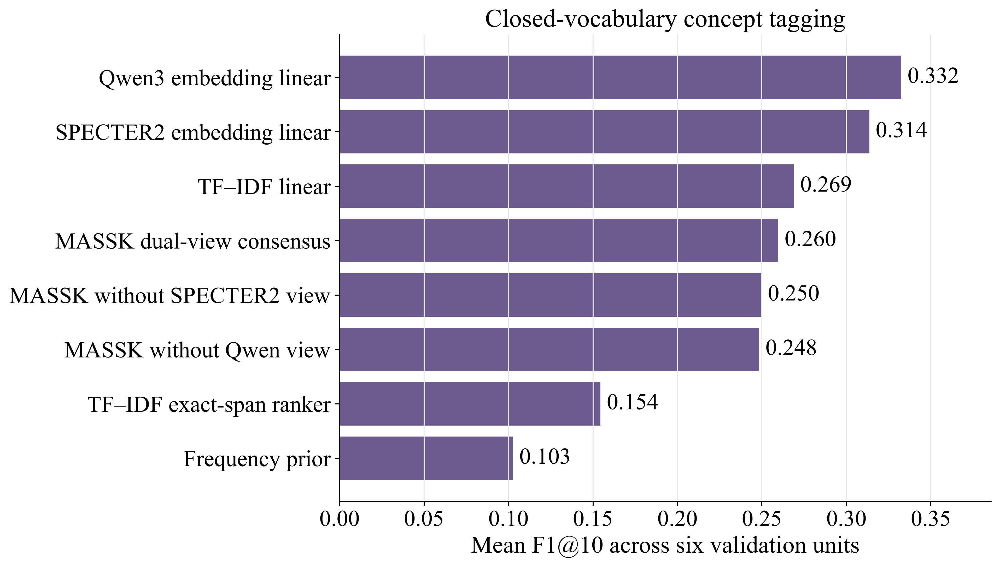

In [19]:
retrieval_plot = (
    retrieval_view[retrieval_view['metric'].eq('ndcg_at_10')]
    .groupby(['model', 'metric'], as_index=False)['value']
    .mean()
)
if retrieval_plot.empty:
    withhold_figure(
        'semantic_retrieval_comparison',
        'semantic_retrieval',
        MISSING['executed'],
        'No trusted round-7 retrieval metrics',
    )
else:
    retrieval_labels = {
        'Fold-local TF–IDF cosine': 'TF–IDF cosine',
        'Jina v5 nano classification frozen cosine': 'Jina v5 nano cosine',
        'MASSK-CORE dual-view score consensus': 'MASSK dual-view consensus',
        'MASSK fixed score consensus': 'MASSK dual-view consensus',
        'MASSK − Qwen retrieval view': 'MASSK without Qwen view',
        'MASSK without Qwen retrieval view': 'MASSK without Qwen view',
        'MASSK − SPECTER2 retrieval view': 'MASSK without SPECTER2 view',
        'MASSK without SPECTER2 retrieval view': 'MASSK without SPECTER2 view',
        'Qwen3-Embedding-0.6B frozen cosine': 'Qwen3 embedding cosine',
        'SPECTER2 classification adapter frozen cosine': 'SPECTER2 adapter cosine',
        'SciNCL frozen cosine': 'SciNCL cosine',
    }
    retrieval_plot['label'] = (
        retrieval_plot['model'].map(retrieval_labels).fillna(retrieval_plot['model'])
    )
    retrieval_plot = retrieval_plot.sort_values('value')
    fig, ax = plt.subplots(figsize=(10.8, 7.2))
    bars = ax.barh(retrieval_plot['label'], retrieval_plot['value'], color=PALETTE['teal'])
    ax.bar_label(
        bars, labels=[f'{value:.3f}' for value in retrieval_plot['value']], fontsize=18, padding=5
    )
    ax.set_xlabel('Mean nDCG@10 across six validation units')
    ax.set_title('Semantic retrieval on a common metric')
    ax.grid(axis='x', color=PALETTE['light_gray'])
    ax.set_xlim(0, max(retrieval_plot['value']) * 1.16)
    fig.subplots_adjust(left=0.31, right=0.97, bottom=0.13, top=0.86)
    save_figure(fig, 'semantic_retrieval_comparison', 'semantic_retrieval')

keyphrase_plot = (
    keyphrase_view[keyphrase_view['metric'].eq('keyphrase_f1_at_10')]
    .groupby(['model', 'metric'], as_index=False)['value']
    .mean()
)
if keyphrase_plot.empty:
    withhold_figure(
        'keyphrase_extraction_comparison',
        'closed_vocabulary_tagging',
        MISSING['executed'],
        'No trusted round-7 concept-tagging metrics',
    )
else:
    keyphrase_labels = {
        'Fold-local frequency prior': 'Frequency prior',
        'MASSK-CORE dual-view tagging consensus': 'MASSK dual-view consensus',
        'MASSK fixed tagging consensus': 'MASSK dual-view consensus',
        'MASSK − Qwen tagging view': 'MASSK without Qwen view',
        'MASSK without Qwen tagging view': 'MASSK without Qwen view',
        'MASSK − SPECTER2 tagging view': 'MASSK without SPECTER2 view',
        'MASSK without SPECTER2 tagging view': 'MASSK without SPECTER2 view',
        'Qwen3 raw-embedding GPU linear OVR': 'Qwen3 embedding linear',
        'SPECTER2 raw-embedding GPU linear OVR': 'SPECTER2 embedding linear',
        'TF–IDF GPU linear OVR': 'TF–IDF linear',
        'TF–IDF exact-span ranker': 'TF–IDF exact-span ranker',
    }
    keyphrase_plot['label'] = (
        keyphrase_plot['model'].map(keyphrase_labels).fillna(keyphrase_plot['model'])
    )
    keyphrase_plot = keyphrase_plot.sort_values('value')
    fig, ax = plt.subplots(figsize=(10.8, 7.2))
    bars = ax.barh(keyphrase_plot['label'], keyphrase_plot['value'], color=PALETTE['purple'])
    ax.bar_label(
        bars, labels=[f'{value:.3f}' for value in keyphrase_plot['value']], fontsize=18, padding=5
    )
    ax.set_xlabel('Mean F1@10 across six validation units')
    ax.set_title('Closed-vocabulary concept tagging')
    ax.grid(axis='x', color=PALETTE['light_gray'])
    ax.set_xlim(0, max(keyphrase_plot['value']) * 1.16)
    fig.subplots_adjust(left=0.31, right=0.97, bottom=0.13, top=0.84)
    save_figure(fig, 'keyphrase_extraction_comparison', 'closed_vocabulary_tagging')

## 8. Robustness, efficiency, and measurement scopes

Robustness is validation-only. Efficiency rows preserve whether they measure cached inference, end-to-end inference, or another explicitly named scope; incomparable scopes are not merged into a single ranking.


In [20]:
if robustness_raw is None:
    final_robustness = pd.DataFrame(
        [
            {
                'condition': MISSING['executed'],
                'metric': MISSING['executed'],
                'value': MISSING['executed'],
                'scope': 'EXPLORATORY_POST_SELECTION_DEVELOPMENT_VALIDATION',
                'status': SYNTHESIS_STATUS,
            }
        ]
    )
else:
    final_robustness = robustness_raw.copy()
    final_robustness['scope'] = 'EXPLORATORY_POST_SELECTION_DEVELOPMENT_VALIDATION'
    final_robustness['authority_status'] = SYNTHESIS_STATUS
_, final_robustness = save_table(
    final_robustness, 'final_robustness_summary.csv', MISSING['executed']
)
robustness_reader_columns = [
    column
    for column in ['condition', 'metric', 'value']
    if column in final_robustness
]
display(
    final_robustness[robustness_reader_columns].head(12).style.hide(axis='index')
    .set_caption('Development-only robustness checks')
)

if efficiency_raw is None:
    final_efficiency = pd.DataFrame(
        [
            {
                'model': MISSING['executed'],
                'measurement_scope': MISSING['executed'],
                'metric': MISSING['executed'],
                'value': MISSING['executed'],
                'comparability_status': MISSING['executed'],
                'status': SYNTHESIS_STATUS,
            }
        ]
    )
else:
    final_efficiency = efficiency_raw.copy()
    final_efficiency = final_efficiency.replace(
        {r'(?i)^not_available(?=;|$)': MISSING['executed']}, regex=True
    )
    scope_col = first_column(
        final_efficiency,
        ['throughput_measurement_scope', 'measurement_scope', 'scope', 'inference_scope'],
    )
    if scope_col is None:
        final_efficiency['measurement_scope'] = MISSING['pending']
        scope_col = 'measurement_scope'
    scope_counts = final_efficiency[scope_col].astype(str).nunique()
    final_efficiency['comparability_status'] = (
        'SAME_DECLARED_SCOPE' if scope_counts == 1 else 'SEPARATE_SCOPES_DO_NOT_RANK_JOINTLY'
    )
    final_efficiency['authority_status'] = SYNTHESIS_STATUS
_, final_efficiency = save_table(
    final_efficiency, 'final_efficiency_summary.csv', MISSING['executed']
)
efficiency_view = final_efficiency[
    [
        column
        for column in [
            'track',
            'massk_full_training_seconds_total',
            'batched_cached_head_throughput_equivalent_ms_per_document',
            'trainable_classifier_head_and_fusion_parameters',
            'throughput_measurement_scope',
            'comparability_status',
        ]
        if column in final_efficiency
    ]
].copy()
display(
    efficiency_view.style.hide(axis='index')
    .set_caption('Cached-head efficiency values retained with their measurement scope')
)

# Forward-active counts differ from stored counts because the experimental class stores all R8 modules.
active_parameters = {
    'R8_MEAN': 351888,
    'R8_STACK': 351890,
    'R8_GATE': 351969,
    'R8_RESIDUAL': 390488,
    'R8_CONCAT': 390392,
    'MASSK_R8_FULL': 390569,
    'R8_QWEN': 200776,
    'R8_SPECTER': 151112,
}
fit_audit = pd.read_csv(TABLES / 'massk_round8_fit_audit.csv', keep_default_na=False)
efficiency_rows = []
for track, group in fit_audit.groupby('track'):
    stored = int(pd.to_numeric(group.parameters).max())
    active = active_parameters[track]
    efficiency_rows.append(
        {
            'model': track,
            'stored_parameters': stored,
            'forward_active_parameters': active,
            'unused_stored_parameters': stored - active,
            'latency_ms_per_paper_mean': pd.to_numeric(group.latency_ms_per_paper).mean(),
            'latency_scope': 'GPU cached-embedding batched head/fusion only; not raw-text or batch-1',
        }
    )
efficiency_rows.append(
    {
        'model': EXPLORATORY_VALIDATION_CANDIDATE,
        'stored_parameters': MISSING['measured'],
        'forward_active_parameters': MISSING['measured'],
        'unused_stored_parameters': MISSING['applicable'],
        'latency_ms_per_paper_mean': MISSING['measured'],
        'latency_scope': 'Two-path end-to-end deployment cost not measured; no efficiency superiority claim',
    }
)
round8_parameter_audit = pd.DataFrame(efficiency_rows)
_, round8_parameter_audit = save_table(
    round8_parameter_audit, 'massk_round8_active_parameter_audit.csv', MISSING['measured']
)
parameter_reader = round8_parameter_audit[
    [
        'model',
        'forward_active_parameters',
        'latency_ms_per_paper_mean',
    ]
].copy()
display(
    parameter_reader.style.hide(axis='index')
    .set_caption('Forward-active parameters and cached-embedding latency')
)

condition
title_only
abstract_removed_or_truncated
token_noise


track,massk_full_training_seconds_total,batched_cached_head_throughput_equivalent_ms_per_document,trainable_classifier_head_and_fusion_parameters,throughput_measurement_scope,comparability_status
MASSK,55.945716,0.028288,5430897,batched cached-head throughput-equivalent ms/document; not single-document latency; excludes tokenization and frozen encoders,SAME_DECLARED_SCOPE
MASSK,59.649223,0.032097,5393325,batched cached-head throughput-equivalent ms/document; not single-document latency; excludes tokenization and frozen encoders,SAME_DECLARED_SCOPE
MASSK,61.435659,0.033616,5410899,batched cached-head throughput-equivalent ms/document; not single-document latency; excludes tokenization and frozen encoders,SAME_DECLARED_SCOPE
MASSK,54.416728,0.025193,5429079,batched cached-head throughput-equivalent ms/document; not single-document latency; excludes tokenization and frozen encoders,SAME_DECLARED_SCOPE
MASSK,51.627269,0.027866,5383629,batched cached-head throughput-equivalent ms/document; not single-document latency; excludes tokenization and frozen encoders,SAME_DECLARED_SCOPE
MASSK,55.285258,0.029175,5415747,batched cached-head throughput-equivalent ms/document; not single-document latency; excludes tokenization and frozen encoders,SAME_DECLARED_SCOPE


model,forward_active_parameters,latency_ms_per_paper_mean
MASSK_R8_FULL,390569,0.002298
R8_CONCAT,390392,0.001299
R8_GATE,351969,0.002011
R8_MEAN,351888,0.001210
R8_QWEN,200776,0.000985
R8_RESIDUAL,390488,0.001449
R8_SPECTER,151112,0.000957
R8_STACK,351890,0.001431
MASSK_CLASSWISE_RETRIEVAL_RESIDUAL,NOT_MEASURED,NOT_MEASURED


## 9. Error structure and explainability

The signed flow view is generated only when matched Full and semantic-only development predictions are both present in the current manifest.


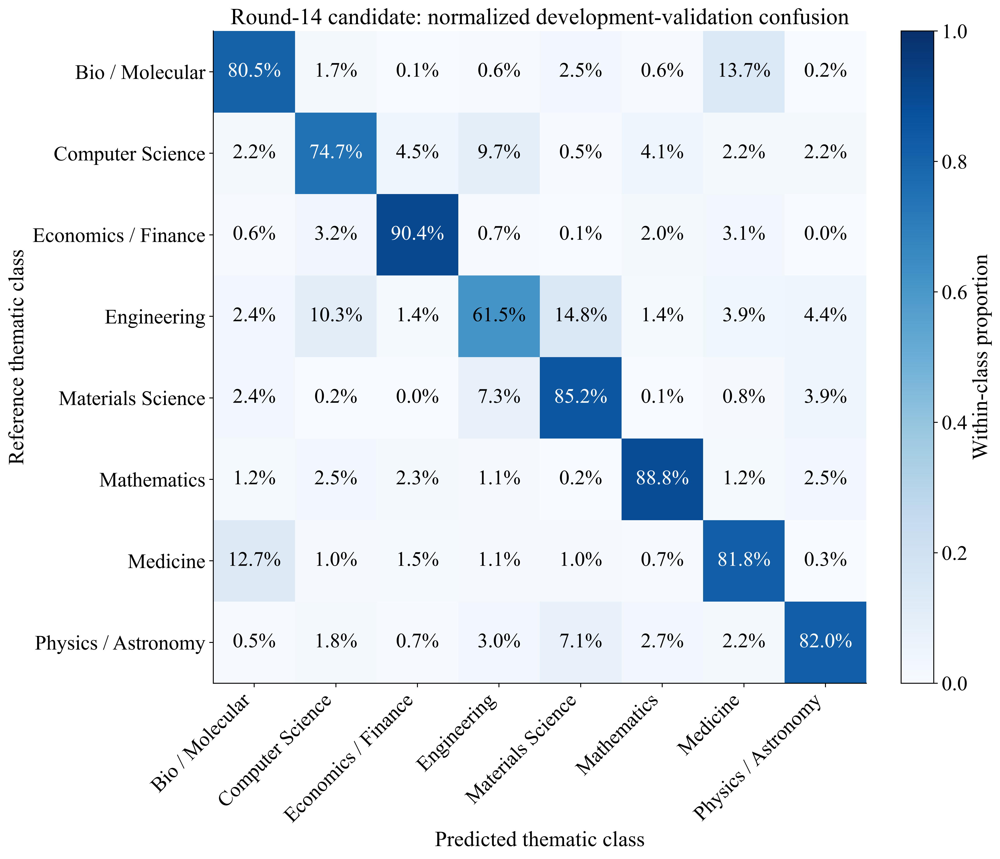

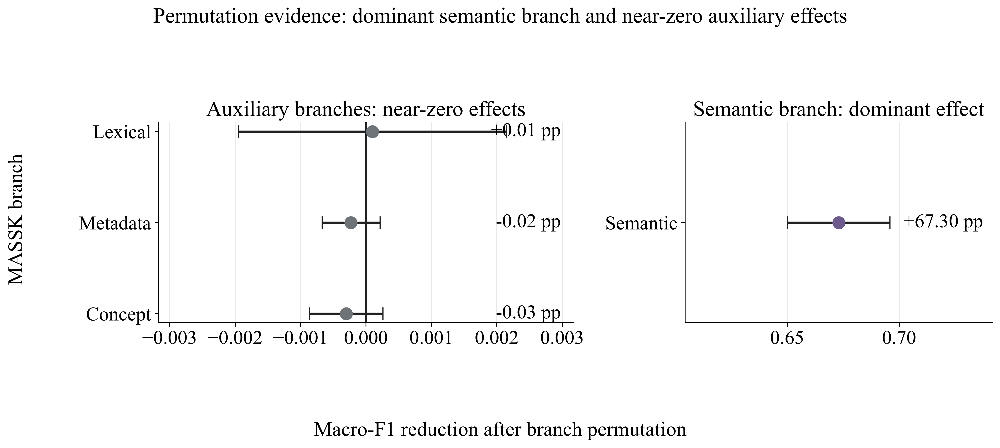

In [21]:
true_col = first_column(analysis_predictions, ['y_true', 'true_label', 'label_id', 'target'])
pred_col = first_column(analysis_predictions, ['y_pred', 'predicted_label', 'prediction'])
confusion_probability_columns = (
    sorted(
        [
            column
            for column in analysis_predictions
            if re.fullmatch(r'probability_\d+', str(column))
        ],
        key=lambda column: int(str(column).rsplit('_', 1)[1]),
    )
    if analysis_predictions is not None
    else []
)
if (
    analysis_predictions is None
    or not true_col
    or (not pred_col and not confusion_probability_columns)
):
    withhold_figure(
        'confusion_matrix_massk',
        'round14_exploratory_candidate_confusion_matrix',
        MISSING['executed'],
        'Round-14 exploratory candidate labels are unavailable',
    )
else:
    if pred_col:
        truth = analysis_predictions[true_col].astype(str)
        predicted = analysis_predictions[pred_col].astype(str)
    else:
        truth_numeric = pd.to_numeric(analysis_predictions[true_col], errors='coerce')
        probability_matrix = (
            analysis_predictions[confusion_probability_columns]
            .apply(pd.to_numeric, errors='coerce')
            .to_numpy()
        )
        valid = truth_numeric.notna().to_numpy() & np.isfinite(probability_matrix).all(axis=1)
        truth = truth_numeric[valid].astype(int).astype(str)
        predicted = pd.Series(probability_matrix[valid].argmax(axis=1)).astype(str)
    labels = sorted(set(truth) | set(predicted))
    matrix = confusion_matrix(truth, predicted, labels=labels, normalize='true')
    fig, ax = plt.subplots(figsize=(13.2, 10.8))
    image = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=1)
    annotate_matrix(
        ax,
        image,
        matrix,
        lambda value: f'{100 * value:.1f}%',
        'round14_exploratory_candidate_confusion_matrix',
    )
    class_names = (
        development[['label_id', 'thematic_class']]
        .drop_duplicates()
        .set_index('label_id')
        .thematic_class.to_dict()
    )
    short_names = {
        0: 'Bio / Molecular',
        1: 'Computer Science',
        2: 'Economics / Finance',
        3: 'Engineering',
        4: 'Materials Science',
        5: 'Mathematics',
        6: 'Medicine',
        7: 'Physics / Astronomy',
    }
    display_labels = [
        short_names.get(int(label), class_names.get(int(label), str(label))) for label in labels
    ]
    ax.set_xticks(range(len(labels)), display_labels, rotation=45, ha='right')
    ax.set_yticks(range(len(labels)), display_labels)
    ax.set_xlabel('Predicted thematic class')
    ax.set_ylabel('Reference thematic class')
    ax.set_title('Round-14 candidate: normalized development-validation confusion')
    colorbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    colorbar.set_label('Within-class proportion')
    fig.tight_layout()
    save_figure(fig, 'confusion_matrix_massk', 'round14_exploratory_candidate_confusion_matrix')

permutation = load_csv('results/tables/explainability_results.csv')
required = {'branch', 'macro_f1_drop'}
if permutation is None or not required.issubset(permutation.columns):
    withhold_figure(
        'explainability_summary',
        'branch_permutation_importance',
        MISSING['executed'],
        'Synchronized branch permutations unavailable',
    )
else:
    permutation['macro_f1_drop'] = pd.to_numeric(permutation['macro_f1_drop'], errors='coerce')
    summary = (
        permutation.dropna(subset=['macro_f1_drop'])
        .groupby('branch', as_index=False)
        .agg(
            mean_macro_f1_drop=('macro_f1_drop', 'mean'),
            sd_macro_f1_drop=('macro_f1_drop', 'std'),
            validation_units=('macro_f1_drop', 'size'),
        )
    )
    summary['approximate_lower_95'] = summary['mean_macro_f1_drop'] - 1.96 * summary[
        'sd_macro_f1_drop'
    ].fillna(0) / np.sqrt(summary['validation_units'])
    summary['interpretation'] = np.where(
        summary['approximate_lower_95'] > 0,
        'STABLE_POSITIVE_PERMUTATION_CONTRIBUTION',
        np.where(
            summary['mean_macro_f1_drop'] > 0,
            'DIRECTIONALLY_POSITIVE_UNCERTAIN',
            'NO_POSITIVE_PERMUTATION_CONTRIBUTION',
        ),
    )
    summary['scope'] = 'SUPPLEMENTAL_DESCRIPTIVE_NOT_RECEIPT_BACKED'
    _, summary = save_table(summary, 'final_explainability_summary.csv', MISSING['applicable'])
    auxiliary = summary[~summary['branch'].astype(str).str.lower().eq('semantic')].sort_values(
        'mean_macro_f1_drop'
    )
    semantic = summary[summary['branch'].astype(str).str.lower().eq('semantic')]
    fig, (ax_aux, ax_sem) = plt.subplots(
        1, 2, figsize=(13.2, 5.8), gridspec_kw={'width_ratios': [1.35, 1.0]}
    )
    for axis, frame, color, title in [
        (ax_aux, auxiliary, PALETTE['gray'], 'Auxiliary branches: near-zero effects'),
        (ax_sem, semantic, PALETTE['purple'], 'Semantic branch: dominant effect'),
    ]:
        positions = np.arange(len(frame))
        means = frame['mean_macro_f1_drop'].to_numpy(float)
        errors = frame['sd_macro_f1_drop'].fillna(0).to_numpy(float)
        axis.errorbar(
            means,
            positions,
            xerr=errors,
            fmt='o',
            color=color,
            ecolor=PALETTE['black'],
            capsize=6,
            markersize=11,
            linewidth=2.2,
        )
        axis.axvline(0, color=PALETTE['black'], linewidth=1.6)
        axis.set_yticks(positions, frame['branch'].astype(str).str.title())
        axis.set_title(title)
        axis.grid(axis='x', color=PALETTE['light_gray'])
        for position, mean in zip(positions, means):
            axis.text(
                0.97,
                position,
                f'{100 * mean:+.2f} pp',
                transform=axis.get_yaxis_transform(),
                ha='right',
                va='center',
                fontsize=18,
            )
    aux_limit = max(
        0.003,
        float(
            (
                auxiliary['mean_macro_f1_drop'].abs()
                + 1.5 * auxiliary['sd_macro_f1_drop'].fillna(0)
            ).max()
        ),
    )
    ax_aux.set_xlim(-aux_limit, aux_limit)
    sem_mean = float(semantic['mean_macro_f1_drop'].iloc[0])
    sem_sd = float(semantic['sd_macro_f1_drop'].iloc[0])
    ax_sem.set_xlim(max(0, sem_mean - 3 * sem_sd), min(1, sem_mean + 3 * sem_sd))
    fig.suptitle(
        'Permutation evidence: dominant semantic branch and near-zero auxiliary effects', y=0.97
    )
    fig.supxlabel('Macro-F1 reduction after branch permutation', fontsize=19)
    fig.supylabel('MASSK branch', fontsize=19)
    fig.tight_layout(rect=(0.03, 0.08, 1, 0.90))
    save_figure(fig, 'explainability_summary', 'branch_permutation_importance')

## 10. Scientific limitations

- All model comparisons are exploratory and use reused development-validation data.
- The Round-14 classification promotion gate failed; classification superiority is not established.
- NLL and Brier intervals are nominal post-hoc results without selection or multiplicity adjustment.
- Previously exposed test and external-test cohorts cannot provide confirmation; a genuinely new cohort is required.

## 11. Bounded retrieval-refinement update

In [22]:

updated_models = pd.read_csv(TABLES / 'final_model_comparison_with_refinement14.csv')
round13_gate = pd.read_csv(TABLES / 'massk_round13_statistical_gate.csv')
round14_gate = pd.read_csv(TABLES / 'massk_round14_statistical_gate.csv')
round14_reliability = pd.read_csv(TABLES / 'massk_round14_secondary_reliability_tests.csv')
candidate14 = updated_models.set_index('model').loc['MASSK_CLASSWISE_RETRIEVAL_RESIDUAL']
assert len(updated_models) == 19 and candidate14.unique_papers == 6708
assert not bool(round13_gate.loc[0, 'scientific_gate_pass'])
assert not bool(round14_gate.loc[0, 'scientific_gate_pass'])
assert round14_reliability.paper_interval_supports_improvement.all()
assert round14_reliability.cluster_interval_supports_improvement.all()
g14 = round14_gate.iloc[0]
display(
    Markdown(
        f'''**Bounded refinement result.** The common development panel contains
        **19 models and 6,708 publications**. The class-wise retrieval-residual
        candidate reached Accuracy **{candidate14.accuracy:.4f}**, Macro-F1
        **{candidate14.macro_f1:.4f}**, MCC **{candidate14.mcc:.4f}**, NLL
        **{candidate14.nll:.4f}**, ECE-15 **{candidate14.ece_15:.4f}**, and
        multiclass Brier **{candidate14.brier_multiclass:.4f}**. Its Macro-F1
        contrast against PRISM-Evidence was **{g14.delta_macro_f1:+.4f}**
        with document-bootstrap 95% interval
        **[{g14.paper_lcb_95:.4f}, {g14.paper_ucb_95:.4f}]**; therefore the
        predeclared classification promotion gate was not met.'''
    )
)


**Bounded refinement result.** The common development panel contains
        **19 models and 6,708 publications**. The class-wise retrieval-residual
        candidate reached Accuracy **0.8099**, Macro-F1
        **0.8057**, MCC **0.7825**, NLL
        **0.5448**, ECE-15 **0.0141**, and
        multiclass Brier **0.2789**. Its Macro-F1
        contrast against PRISM-Evidence was **+0.0005**
        with document-bootstrap 95% interval
        **[-0.0026, 0.0035]**; therefore the
        predeclared classification promotion gate was not met.

### Statistical interpretation boundary

Round 14 did not use test or external-test outcomes. Its classification result is negative under the predeclared promotion rule. The NLL and Brier differences are reported only as nominal post-hoc development-validation signals and require independent confirmation.

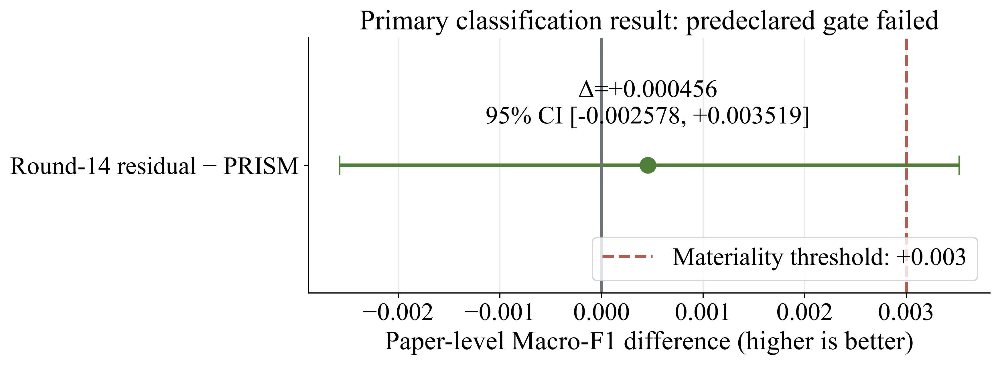

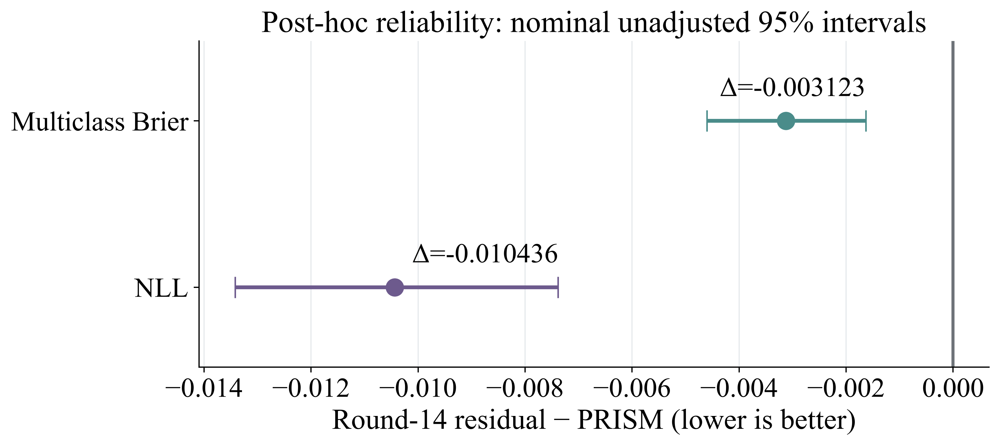

In [23]:
gate_plot = pd.read_csv(TABLES / 'massk_round14_statistical_gate.csv').iloc[0]
reliability_plot = pd.read_csv(TABLES / 'massk_round14_secondary_reliability_tests.csv').set_index(
    'metric'
)

fig, ax = plt.subplots(figsize=(10.0, 4.4))
delta = float(gate_plot.delta_macro_f1)
lo = float(gate_plot.paper_lcb_95)
hi = float(gate_plot.paper_ucb_95)
ax.errorbar(
    [delta],
    [0],
    xerr=[[delta - lo], [hi - delta]],
    fmt='o',
    markersize=11,
    capsize=7,
    color=PALETTE['green'],
    linewidth=2.5,
)
ax.axvline(0, color=PALETTE['gray'], linewidth=2)
ax.axvline(
    0.003,
    color=PALETTE['red'],
    linestyle='--',
    linewidth=2.2,
    label='Materiality threshold: +0.003',
)
ax.set_yticks([0], ['Round-14 residual − PRISM'])
ax.set_ylim(-0.46, 0.46)
ax.set_xlabel('Paper-level Macro-F1 difference (higher is better)')
ax.set_title('Primary classification result: predeclared gate failed')
ax.text(
    delta,
    0.22,
    f'Δ={delta:+.6f}\n95% CI [{lo:+.6f}, {hi:+.6f}]',
    ha='center',
    va='center',
    fontsize=18,
)
ax.grid(axis='x', color=PALETTE['light_gray'])
ax.legend(loc='lower right', frameon=True, facecolor='white')
fig.subplots_adjust(left=0.29, right=0.97, bottom=0.22, top=0.80)
save_figure(fig, 'model_comparison_refinement14_macro_f1', 'round14_primary_macro_f1_gate')

fig, ax = plt.subplots(figsize=(10.0, 4.8))
for y_pos, (metric, label, color) in enumerate(
    [('nll', 'NLL', PALETTE['purple']), ('brier_multiclass', 'Multiclass Brier', PALETTE['teal'])]
):
    row = reliability_plot.loc[metric]
    d = float(row.candidate_minus_anchor)
    lo = float(row.paper_lcb_95)
    hi = float(row.paper_ucb_95)
    ax.errorbar(
        [d],
        [y_pos],
        xerr=[[d - lo], [hi - d]],
        fmt='o',
        markersize=11,
        capsize=7,
        color=color,
        linewidth=2.5,
    )
    ax.text(hi, y_pos + 0.15, f'Δ={d:+.6f}', fontsize=18, ha='right')
ax.axvline(0, color=PALETTE['gray'], linewidth=2)
ax.set_yticks([0, 1], ['NLL', 'Multiclass Brier'])
ax.set_ylim(-0.48, 1.48)
ax.set_xlabel('Round-14 residual − PRISM (lower is better)')
ax.set_title('Post-hoc reliability: nominal unadjusted 95% intervals')
ax.grid(axis='x', color=PALETTE['light_gray'])
fig.subplots_adjust(left=0.25, right=0.97, bottom=0.20, top=0.82)
save_figure(fig, 'model_comparison_refinement14_nll', 'round14_nominal_reliability_intervals')

## 12. Fixed retrospective temporal and external stress evaluation

This section evaluates the fixed development-only realization of **PRISM-Evidence**
and the proposed **MASSK class-wise retrieval residual** on:

- **Temporal 2025 stress:** 1,914 OpenAlex publications;
- **External arXiv stress:** 1,181 arXiv publications.

> **Evidence boundary.** These cohorts existed in the project before this evaluation
> protocol was frozen. The results are therefore retrospective temporal/external
> stress evidence, **not an independent confirmatory test**. Their labels were not
> used for fitting, early stopping, calibration, selection of the eight retrieval
> coefficients, or any post-result hyperparameter adjustment. The reliability metric
> is negative log-likelihood (**NLL**, not “NLI”).

In [24]:
from hashlib import sha256

stress_protocol = json.loads(
    (MODELS / 'retrospective_stress_evaluation_protocol_lock_v2.json').read_text()
)
stress_model_lock = json.loads(
    (MODELS / 'retrospective_stress_model_pre_evaluation_lock_v2.json').read_text()
)
stress_receipt = json.loads(
    (MODELS / 'retrospective_stress_evaluation_execution_receipt_v2.json').read_text()
)

stress_files = {
    'metrics': TABLES / 'retrospective_stress_metrics.csv',
    'intervals': TABLES / 'retrospective_stress_confidence_intervals.csv',
    'deltas': TABLES / 'retrospective_stress_paired_deltas.csv',
    'per_class': TABLES / 'retrospective_stress_per_class_f1.csv',
    'confusion': TABLES / 'retrospective_stress_confusion_matrices.csv',
    'retrieval': TABLES / 'retrospective_stress_retrieval_metrics.csv',
    'timing': TABLES / 'retrospective_stress_timing.csv',
    'parameters': TABLES / 'retrospective_stress_parameters.csv',
    'heaps': TABLES / 'retrospective_stress_heaps_law.csv',
    'fit': TABLES / 'retrospective_stress_model_fit_audit.csv',
    'environment': TABLES / 'retrospective_stress_environment.csv',
}

for path in stress_files.values():
    assert path.exists(), f'Missing stress-evaluation artifact: {path.name}'
    digest = sha256(path.read_bytes()).hexdigest()
    assert stress_receipt['output_sha256'][path.name] == digest

assert stress_receipt['protocol_sha256'] == stress_protocol['protocol_sha256']
assert stress_model_lock['protocol_sha256'] == stress_protocol['protocol_sha256']
assert stress_receipt['pre_evaluation_model_lock_sha256'] == sha256(
    (MODELS / 'retrospective_stress_model_pre_evaluation_lock_v2.json').read_bytes()
).hexdigest()
assert stress_model_lock['stress_labels_parsed_before_lock'] is False
assert stress_receipt['test_rows_loaded_for_training_or_tuning'] == 0
assert stress_receipt['external_rows_loaded_for_training_or_tuning'] == 0
assert stress_receipt['temporal_rows_evaluated'] == 1914
assert stress_receipt['external_rows_evaluated'] == 1181

stress_metrics = pd.read_csv(stress_files['metrics'])
stress_intervals = pd.read_csv(stress_files['intervals'])
stress_deltas = pd.read_csv(stress_files['deltas'])
stress_per_class = pd.read_csv(stress_files['per_class'])
stress_confusion = pd.read_csv(stress_files['confusion'])
stress_retrieval = pd.read_csv(stress_files['retrieval'])
stress_timing = pd.read_csv(stress_files['timing'])
stress_parameters = pd.read_csv(stress_files['parameters'])
stress_heaps = pd.read_csv(stress_files['heaps'])
stress_fit = pd.read_csv(stress_files['fit'])
stress_environment = pd.read_csv(stress_files['environment'], keep_default_na=False)

evidence_status = pd.DataFrame(
    [
        {
            'Protocol': stress_protocol['config']['protocol_id'],
            'Claim status': 'RETROSPECTIVE STRESS EVIDENCE',
            'Temporal rows': stress_receipt['temporal_rows_evaluated'],
            'External rows': stress_receipt['external_rows_evaluated'],
            'Stress labels used for fit/tuning': 'NO',
            'Exact weights locked before v2 stress parsing': 'YES',
            'Processor': stress_receipt['cuda_device'],
            'Protocol SHA-256': stress_protocol['protocol_sha256'][:16],
            'Model SHA-256': stress_model_lock['model_bundle_sha256'][:16],
        }
    ]
)
display(
    evidence_status.style.hide(axis='index')
    .set_caption('Frozen protocol and execution scope')
)

Protocol,Claim status,Temporal rows,External rows,Stress labels used for fit/tuning,Exact weights locked before v2 stress parsing,Processor,Protocol SHA-256,Model SHA-256
MASSK-RETROSPECTIVE-STRESS-v2,RETROSPECTIVE STRESS EVIDENCE,1914,1181,NO,YES,NVIDIA GeForce RTX 5070 Laptop GPU,2ffeec898851273e,857cce983b95a52e


### 12.1. Frozen model specification

The comparison uses a common PRISM-Evidence posterior. MASSK changes only the
class-wise uncertainty-scaled Top-5 retrieval residual. Consequently, the paired
contrast isolates the proposed residual mechanism rather than comparing unrelated
training pipelines.

In [25]:
complete_specification = pd.read_csv(
    TABLES / 'retrospective_stress_frozen_specification_complete.csv',
    keep_default_na=False,
)
specification_groups = {
    'Pinned encoders and preprocessing': [
        'Qwen3 encoder',
        'SPECTER2 encoder',
    ],
    'Fixed atomic and interaction learners': [
        'Atomic paths',
        'Interaction path',
    ],
    'Fixed routing, retrieval, decision, and seeds': [
        'Evidence router',
        'Retrieval',
        'Decision',
        'Seeds',
    ],
    'Fixed MASSK retrieval-residual coefficients': [
        'MASSK residual',
    ],
}
for title, components in specification_groups.items():
    view = complete_specification[
        complete_specification['Component'].isin(components)
    ].copy()
    display(
        view.style.hide(axis='index')
        .set_properties(
            subset=['Frozen value', 'Selection source'],
            **{'max-width': '520px', 'white-space': 'normal'},
        )
        .set_caption(title)
    )


Component,Parameter,Frozen value,Selection source
Qwen3 encoder,Model,Qwen/Qwen3-Embedding-0.6B,pinned before benchmark
Qwen3 encoder,Revision,97b0c614be4d77ee51c0cef4e5f07c00f9eb65b3,pinned before benchmark
Qwen3 encoder,Pooling,last-token; L2-normalized,fixed preprocessing
Qwen3 encoder,Input,Instruct: Represent the scientific paper for broad thematic classification into eight research fields. Query:,fixed preprocessing
Qwen3 encoder,Maximum length / batch,512 tokens / 24 documents,fixed preprocessing
SPECTER2 encoder,Base model,allenai/specter2_base,pinned before benchmark
SPECTER2 encoder,Base revision,3447645e1def9117997203454fa4495937bfbd83,pinned before benchmark
SPECTER2 encoder,Adapter,allenai/specter2_classification,pinned before benchmark
SPECTER2 encoder,Adapter revision,d843816b414a856d9a5268d5865f188bb589e6e1,pinned before benchmark
SPECTER2 encoder,Pooling / normalization,CLS; L2-normalized,fixed preprocessing


Component,Parameter,Frozen value,Selection source
Atomic paths,Projection width / dropout,192 / 0.1,development only
Atomic paths,Optimizer,AdamW; lr=0.0007; weight_decay=0.004,development only
Atomic paths,Epoch cap / scheduler,44 / cosine annealing,development only
Atomic paths,Training batch / gradient clipping,384 / 2.0,development only
Atomic paths,Loss / clipping,class-balanced cross-entropy; label smoothing=0.025; clip=2.0,development only
Interaction path,Rank / dropout / residual cap,64 / 0.12 / 0.35,development only
Interaction path,Optimizer,AdamW; lr=0.0008; weight_decay=0.006,development only
Interaction path,Epoch cap / training batch,45 / 512,development only
Interaction path,Loss / clipping,class-balanced cross-entropy + 0.12 atomic auxiliary loss; label smoothing=0.02; clip=2.0,development only


Component,Parameter,Frozen value,Selection source
Evidence router,Trainable parameters / range,"22 / alpha in [0.20, 0.80]",development OOF only
Evidence router,Optimizer,AdamW; lr=0.02; weight_decay=0.03,development OOF only
Evidence router,Epoch cap / patience,220 / 24,development OOF only
Evidence router,Fold roles,stop outer fold=0; calibration outer fold=1,pre-specified
Evidence router,Temperature-selection rule,use only if NLL and Brier improve and ECE-15 does not worsen by more than 0.001,pre-specified
Evidence router,Activation gate,Macro-F1 delta >= 0.001; reliability tolerance=0.002,pre-specified
Retrieval,Index / neighbours,6708 development documents / exact Top-5,fixed before stress evaluation
Retrieval,Similarity / temperature,mean Qwen3+SPECTER2 cosine / 0.07,Round-14 development protocol
Decision,Rule / primary metric / comparator,argmax of the eight-class posterior; no abstention threshold / Macro-F1 / PRISM-Evidence,pre-specified
Seeds,Atomic / interaction / router,"[20260417, 20260519, 20260623] / [20260417, 20260511, 20260623] / [20260721, 20260731, 20260807]",pre-specified


Component,Parameter,Frozen value,Selection source
MASSK residual,Uncertainty,1 - max PRISM posterior,Round-14 development protocol
MASSK residual,gamma_0,0.127662,mean across six development-only contexts
MASSK residual,gamma_1,0.034780,mean across six development-only contexts
MASSK residual,gamma_2,0.182610,mean across six development-only contexts
MASSK residual,gamma_3,0.092038,mean across six development-only contexts
MASSK residual,gamma_4,0.165421,mean across six development-only contexts
MASSK residual,gamma_5,0.138712,mean across six development-only contexts
MASSK residual,gamma_6,0.128050,mean across six development-only contexts
MASSK residual,gamma_7,0.136822,mean across six development-only contexts


In [26]:
fit_summary = (
    stress_fit.groupby('Component', as_index=False)
    .agg(
        Seeds=('Seed', lambda values: ', '.join(map(str, values))),
        Fits=('Seed', 'size'),
        Fit_rows=('Fit rows', 'first'),
        Stop_rows=('Stop rows', 'first'),
        Best_epoch_min=('Best epoch', 'min'),
        Best_epoch_max=('Best epoch', 'max'),
        Active_fits=('Active', 'sum'),
    )
    .rename(
        columns={
            'Fit_rows': 'Fit rows',
            'Stop_rows': 'Early-stop rows',
            'Best_epoch_min': 'Earliest selected epoch',
            'Best_epoch_max': 'Latest selected epoch',
            'Active_fits': 'Active fits',
        }
    )
)
display(
    fit_summary.style.hide(axis='index')
    .format(
        {
            'Fit rows': '{:,.0f}',
            'Early-stop rows': '{:,.0f}',
            'Earliest selected epoch': '{:.0f}',
            'Latest selected epoch': '{:.0f}',
            'Active fits': '{:.0f}',
        }
    )
    .set_caption('Development-only fit and early-stopping summary')
)
display(
    Markdown(
        '**Scientific interpretation.** All classifier and router choices were made '
        'from development folds. The three evidence-router fits did not satisfy the '
        'pre-specified activation gate and therefore reverted to the exact 0.5 path '
        'blend. This fail-closed behavior prevents unsupported router adaptation from '
        'entering the stress comparison.'
    )
)

Component,Seeds,Fits,Fit rows,Early-stop rows,Earliest selected epoch,Latest selected epoch,Active fits
PRISM evidence router,"20260721, 20260731, 20260807",3,"2,236","2,236",1,1,0
Qwen3 atomic path,"20260417, 20260519, 20260623",3,"4,472","2,236",4,6,3
Qwen3-SPECTER2 interaction path,"20260417, 20260511, 20260623",3,"4,472","2,236",8,14,3
SPECTER2 atomic path,"20260417, 20260519, 20260623",3,"4,472","2,236",12,16,3


**Scientific interpretation.** All classifier and router choices were made from development folds. The three evidence-router fits did not satisfy the pre-specified activation gate and therefore reverted to the exact 0.5 path blend. This fail-closed behavior prevents unsupported router adaptation from entering the stress comparison.

### 12.2. Classification, calibration, uncertainty, and paired intervals

Bold values identify the better point estimate **within each cohort**. Higher is
better for Accuracy, Balanced Accuracy, Macro-F1, MCC, and Error AUROC; lower is
better for NLL, Brier score, ECE-15, and AURC. Bold type is descriptive and does not
replace the paired 95% interval. Intervals resample documents and do not model residual
author/institution dependence; they may therefore be anti-conservative and are not
cluster-robust intervals.

In [27]:
higher_metrics = {
    'Accuracy',
    'Balanced Accuracy',
    'Macro-F1',
    'MCC',
    'Error AUROC',
}
metric_columns = [
    'Accuracy',
    'Balanced Accuracy',
    'Macro-F1',
    'MCC',
    'NLL',
    'Brier score',
    'ECE-15',
    'Error AUROC',
    'AURC',
]

def highlight_best_metric(column):
    numeric = pd.to_numeric(column, errors='coerce')
    best = numeric.max() if column.name in higher_metrics else numeric.min()
    return [
        'font-weight: bold; background-color: #E7F2EA'
        if np.isclose(value, best, rtol=0, atol=5e-13)
        else ''
        for value in numeric
    ]

for cohort in stress_metrics['Cohort'].drop_duplicates():
    view = stress_metrics.loc[
        stress_metrics['Cohort'].eq(cohort),
        ['Model', 'N', *metric_columns],
    ].copy()
    display(
        view.style.hide(axis='index')
        .format({'N': '{:,.0f}', **{metric: '{:.4f}' for metric in metric_columns}})
        .apply(highlight_best_metric, subset=metric_columns)
        .set_caption(f'{cohort}: fixed-model performance')
    )

Model,N,Accuracy,Balanced Accuracy,Macro-F1,MCC,NLL,Brier score,ECE-15,Error AUROC,AURC
PRISM-Evidence,"1,914",0.7732,0.7740,0.7732,0.7413,0.6646,0.3307,0.0433,0.7661,0.0993
MASSK,"1,914",0.7774,0.7782,0.7772,0.7462,0.6614,0.3299,0.0470,0.7617,0.0983


Model,N,Accuracy,Balanced Accuracy,Macro-F1,MCC,NLL,Brier score,ECE-15,Error AUROC,AURC
PRISM-Evidence,"1,181",0.5597,0.5604,0.5509,0.5087,1.5147,0.6572,0.2137,0.6657,0.3150
MASSK,"1,181",0.5597,0.5605,0.5499,0.5092,1.5614,0.6693,0.2367,0.6651,0.3153


In [28]:
interval_ready = stress_intervals.copy()
interval_ready['Estimate [95% bootstrap CI]'] = interval_ready.apply(
    lambda row: (
        f"{row['Estimate']:.4f} "
        f"[{row['CI lower']:.4f}, {row['CI upper']:.4f}]"
    ),
    axis=1,
)
for family, family_metrics in {
    'Classification and error detection': [
        'Accuracy',
        'Balanced Accuracy',
        'Macro-F1',
        'MCC',
        'Error AUROC',
    ],
    'Probabilistic reliability and selective risk': [
        'NLL',
        'Brier score',
        'ECE-15',
        'AURC',
    ],
}.items():
    interval_view = interval_ready[
        interval_ready['Metric'].isin(family_metrics)
    ].pivot(
        index=['Cohort', 'Model'],
        columns='Metric',
        values='Estimate [95% bootstrap CI]',
    ).reset_index()
    interval_view.columns.name = None
    display(
        interval_view.style.hide(axis='index')
        .set_properties(**{'white-space': 'nowrap'})
        .set_caption(
            f'{family}: point estimates and document-bootstrap 95% confidence intervals'
        )
    )

Cohort,Model,Accuracy,Balanced Accuracy,Error AUROC,MCC,Macro-F1
External arXiv stress,MASSK,"0.5597 [0.5326, 0.5885]","0.5605 [0.5341, 0.5872]","0.6651 [0.6341, 0.6962]","0.5092 [0.4788, 0.5409]","0.5499 [0.5205, 0.5781]"
External arXiv stress,PRISM-Evidence,"0.5597 [0.5318, 0.5876]","0.5604 [0.5356, 0.5849]","0.6657 [0.6359, 0.6969]","0.5087 [0.4789, 0.5383]","0.5509 [0.5221, 0.5783]"
Temporal 2025 stress,MASSK,"0.7774 [0.7586, 0.7941]","0.7782 [0.7598, 0.7944]","0.7617 [0.7366, 0.7860]","0.7462 [0.7249, 0.7651]","0.7772 [0.7582, 0.7934]"
Temporal 2025 stress,PRISM-Evidence,"0.7732 [0.7550, 0.7915]","0.7740 [0.7562, 0.7921]","0.7661 [0.7418, 0.7895]","0.7413 [0.7201, 0.7619]","0.7732 [0.7548, 0.7908]"


Cohort,Model,AURC,Brier score,ECE-15,NLL
External arXiv stress,MASSK,"0.3153 [0.2820, 0.3512]","0.6693 [0.6280, 0.7120]","0.2367 [0.2102, 0.2655]","1.5614 [1.4550, 1.6725]"
External arXiv stress,PRISM-Evidence,"0.3150 [0.2818, 0.3482]","0.6572 [0.6182, 0.6966]","0.2137 [0.1890, 0.2409]","1.5147 [1.4145, 1.6175]"
Temporal 2025 stress,MASSK,"0.0983 [0.0854, 0.1126]","0.3299 [0.3075, 0.3544]","0.0470 [0.0359, 0.0670]","0.6614 [0.6153, 0.7122]"
Temporal 2025 stress,PRISM-Evidence,"0.0993 [0.0856, 0.1138]","0.3307 [0.3080, 0.3555]","0.0433 [0.0312, 0.0629]","0.6646 [0.6200, 0.7130]"


In [29]:
delta_view = stress_deltas[
    stress_deltas['Metric'].isin(
        [
            'Accuracy',
            'Balanced Accuracy',
            'Macro-F1',
            'MCC',
            'NLL',
            'Brier score',
            'ECE-15',
            'Error AUROC',
            'AURC',
        ]
    )
].copy()
delta_view['Delta [95% paired CI]'] = delta_view.apply(
    lambda row: (
        f"{row['Delta']:+.4f} "
        f"[{row['CI lower']:+.4f}, {row['CI upper']:+.4f}]"
    ),
    axis=1,
)
def paired_evidence_status(row):
    if bool(row['Interval supports improvement']):
        return 'MASSK BETTER'
    if row['Favourable direction'] == 'positive':
        supported_harm = row['CI upper'] < 0
    else:
        supported_harm = row['CI lower'] > 0
    return 'PRISM BETTER' if supported_harm else 'UNRESOLVED'

delta_view['Paired evidence'] = delta_view.apply(paired_evidence_status, axis=1)
display(
    delta_view[
        ['Cohort', 'Metric', 'Delta [95% paired CI]', 'Favourable direction', 'Paired evidence']
    ].style.hide(axis='index')
    .map(
        lambda value: (
            'font-weight: bold; color: #2F6B3A'
            if value == 'MASSK BETTER'
            else (
                'font-weight: bold; color: #9B2C2C'
                if value == 'PRISM BETTER'
                else (
                    'font-weight: bold; color: #8A6D1D'
                    if value == 'UNRESOLVED'
                    else ''
                )
            )
        )
    )
    .set_caption('Paired MASSK minus PRISM-Evidence contrasts')
)

Cohort,Metric,Delta [95% paired CI],Favourable direction,Paired evidence
Temporal 2025 stress,Accuracy,"+0.0042 [-0.0010, +0.0099]",positive,UNRESOLVED
Temporal 2025 stress,Balanced Accuracy,"+0.0042 [-0.0010, +0.0100]",positive,UNRESOLVED
Temporal 2025 stress,Macro-F1,"+0.0040 [-0.0010, +0.0097]",positive,UNRESOLVED
Temporal 2025 stress,MCC,"+0.0049 [-0.0011, +0.0115]",positive,UNRESOLVED
Temporal 2025 stress,NLL,"-0.0031 [-0.0102, +0.0039]",negative,UNRESOLVED
Temporal 2025 stress,Brier score,"-0.0008 [-0.0042, +0.0024]",negative,UNRESOLVED
Temporal 2025 stress,ECE-15,"+0.0037 [-0.0086, +0.0152]",negative,UNRESOLVED
Temporal 2025 stress,Error AUROC,"-0.0045 [-0.0151, +0.0052]",positive,UNRESOLVED
Temporal 2025 stress,AURC,"-0.0010 [-0.0021, +0.0001]",negative,UNRESOLVED
External arXiv stress,Accuracy,"+0.0000 [-0.0068, +0.0059]",positive,UNRESOLVED


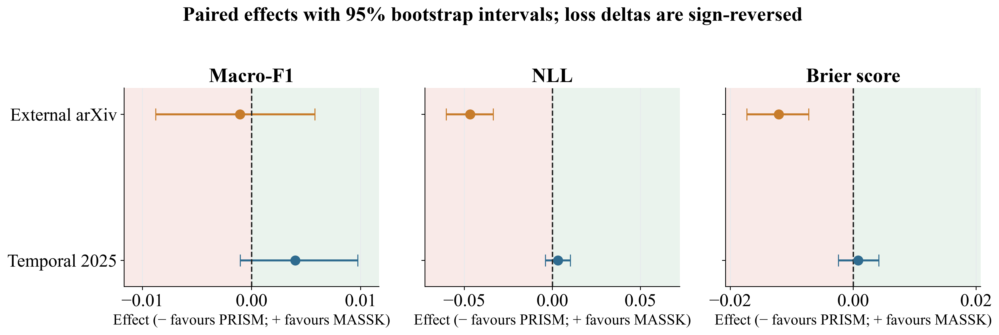

In [30]:
forest_metrics = ['Macro-F1', 'NLL', 'Brier score']
forest = stress_deltas[stress_deltas['Metric'].isin(forest_metrics)].copy()
forest['Direction multiplier'] = np.where(forest['Metric'].eq('Macro-F1'), 1.0, -1.0)
forest['Favourable effect'] = forest['Delta'] * forest['Direction multiplier']
forest['Favourable lower'] = np.where(
    forest['Direction multiplier'].gt(0),
    forest['CI lower'],
    -forest['CI upper'],
)
forest['Favourable upper'] = np.where(
    forest['Direction multiplier'].gt(0),
    forest['CI upper'],
    -forest['CI lower'],
)

fig, axes = plt.subplots(1, 3, figsize=(13.8, 5.1))
cohort_labels = ['Temporal 2025', 'External arXiv']
cohort_colors = [PALETTE['blue'], PALETTE['orange']]
for panel_id, (ax, metric) in enumerate(zip(axes, forest_metrics)):
    part = forest[forest['Metric'].eq(metric)].set_index('Cohort').loc[
        ['Temporal 2025 stress', 'External arXiv stress']
    ]
    limit = 1.20 * max(abs(part['Favourable lower']).max(), abs(part['Favourable upper']).max())
    ax.axvspan(-limit, 0, color='#F8E7E5', alpha=0.85)
    ax.axvspan(0, limit, color='#E7F2EA', alpha=0.85)
    for position, (_, row) in enumerate(part.iterrows()):
        ax.errorbar(
            row['Favourable effect'],
            position,
            xerr=[
                [row['Favourable effect'] - row['Favourable lower']],
                [row['Favourable upper'] - row['Favourable effect']],
            ],
            fmt='o',
            color=cohort_colors[position],
            ecolor=cohort_colors[position],
            capsize=6,
            markersize=9,
            linewidth=2,
        )
    ax.axvline(0, color=PALETTE['black'], linewidth=1.4, linestyle='--')
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-0.18, 1.18)
    if panel_id == 0:
        ax.set_yticks([0, 1], cohort_labels)
    else:
        ax.set_yticks([0, 1], ['', ''])
    ax.set_title(metric, fontweight='bold')
    ax.set_xlabel('Effect (− favours PRISM; + favours MASSK)', fontsize=15)
    ax.grid(axis='x', color=PALETTE['light_gray'], linewidth=0.8)
fig.suptitle(
    'Paired effects with 95% bootstrap intervals; loss deltas are sign-reversed',
    fontsize=20,
    fontweight='bold',
)
fig.subplots_adjust(left=0.13, right=0.99, bottom=0.22, top=0.76, wspace=0.18)
save_figure(fig, 'retrospective_stress_paired_effects')

In [31]:
temporal_delta = stress_deltas[
    stress_deltas['Cohort'].eq('Temporal 2025 stress')
    & stress_deltas['Metric'].eq('Macro-F1')
].iloc[0]
external_delta = stress_deltas[
    stress_deltas['Cohort'].eq('External arXiv stress')
    & stress_deltas['Metric'].eq('Macro-F1')
].iloc[0]
external_nll = stress_deltas[
    stress_deltas['Cohort'].eq('External arXiv stress')
    & stress_deltas['Metric'].eq('NLL')
].iloc[0]
external_brier = stress_deltas[
    stress_deltas['Cohort'].eq('External arXiv stress')
    & stress_deltas['Metric'].eq('Brier score')
].iloc[0]

display(
    Markdown(
        f'''
**Article-ready interpretation.** On the temporal 2025 stress cohort, MASSK
increased Macro-F1 by **{temporal_delta['Delta']:+.4f}** relative to
PRISM-Evidence, but the paired 95% bootstrap interval
[{temporal_delta['CI lower']:+.4f}, {temporal_delta['CI upper']:+.4f}]
included zero. On the external arXiv stress cohort, the Macro-F1 contrast was
**{external_delta['Delta']:+.4f}**
[{external_delta['CI lower']:+.4f}, {external_delta['CI upper']:+.4f}].
External reliability deteriorated: NLL changed by
**{external_nll['Delta']:+.4f}**
[{external_nll['CI lower']:+.4f}, {external_nll['CI upper']:+.4f}] and the
multiclass Brier score by **{external_brier['Delta']:+.4f}**
[{external_brier['CI lower']:+.4f}, {external_brier['CI upper']:+.4f}].
Accordingly, these stress results do **not** establish general superiority of
MASSK over PRISM-Evidence. They show a small, statistically unresolved temporal
classification gain and a statistically supported deterioration in probabilistic
reliability/calibration on this retrospective external cohort.
'''
    )
)


**Article-ready interpretation.** On the temporal 2025 stress cohort, MASSK
increased Macro-F1 by **+0.0040** relative to
PRISM-Evidence, but the paired 95% bootstrap interval
[-0.0010, +0.0097]
included zero. On the external arXiv stress cohort, the Macro-F1 contrast was
**-0.0011**
[-0.0088, +0.0058].
External reliability deteriorated: NLL changed by
**+0.0467**
[+0.0336, +0.0603] and the
multiclass Brier score by **+0.0121**
[+0.0072, +0.0173].
Accordingly, these stress results do **not** establish general superiority of
MASSK over PRISM-Evidence. They show a small, statistically unresolved temporal
classification gain and a statistically supported deterioration in probabilistic
reliability/calibration on this retrospective external cohort.


### 12.3. Per-class behavior and confusion matrices

Per-class values are reported for every thematic field. F1 intervals use the same
document-level bootstrap as the aggregate table. Confusion matrices show raw counts,
so class support remains visible.

In [32]:

stress_per_class_ci = pd.read_csv(
    TABLES / 'retrospective_stress_per_class_metrics_with_ci.csv'
)
for cohort in stress_per_class_ci['Cohort'].drop_duplicates():
    class_view = stress_per_class_ci[
        stress_per_class_ci['Cohort'].eq(cohort)
    ].copy()
    for metric in ['Precision', 'Recall', 'F1']:
        class_view[f'{metric} [95% CI]'] = class_view.apply(
            lambda row: (
                f"{row[metric]:.3f} "
                f"[{row[f'{metric} CI lower']:.3f}, "
                f"{row[f'{metric} CI upper']:.3f}]"
            ),
            axis=1,
        )
    display(
        class_view[
            [
                'Model',
                'Class',
                'Support',
                'Precision [95% CI]',
                'Recall [95% CI]',
                'F1 [95% CI]',
            ]
        ].style.hide(axis='index')
        .format({'Support': '{:,.0f}'})
        .set_caption(f'{cohort}: per-class estimates and document-bootstrap intervals')
    )


Model,Class,Support,Precision [95% CI],Recall [95% CI],F1 [95% CI]
PRISM-Evidence,"Biochemistry, genetics and molecular biology",240,"0.744 [0.690, 0.795]","0.775 [0.723, 0.827]","0.759 [0.715, 0.800]"
PRISM-Evidence,Computer science,242,"0.760 [0.702, 0.818]","0.682 [0.620, 0.739]","0.719 [0.670, 0.764]"
PRISM-Evidence,"Economics, econometrics and finance",237,"0.883 [0.841, 0.921]","0.895 [0.854, 0.930]","0.889 [0.857, 0.917]"
PRISM-Evidence,Engineering,243,"0.691 [0.631, 0.748]","0.663 [0.600, 0.724]","0.676 [0.624, 0.724]"
PRISM-Evidence,Materials science,239,"0.739 [0.681, 0.795]","0.782 [0.728, 0.834]","0.760 [0.716, 0.802]"
PRISM-Evidence,Mathematics,235,"0.842 [0.793, 0.884]","0.860 [0.814, 0.901]","0.851 [0.815, 0.883]"
PRISM-Evidence,Medicine,237,"0.708 [0.650, 0.760]","0.819 [0.770, 0.865]","0.759 [0.716, 0.798]"
PRISM-Evidence,Physics and astronomy,241,"0.836 [0.785, 0.885]","0.718 [0.660, 0.775]","0.772 [0.728, 0.813]"
MASSK,"Biochemistry, genetics and molecular biology",240,"0.762 [0.708, 0.815]","0.787 [0.731, 0.838]","0.775 [0.729, 0.815]"
MASSK,Computer science,242,"0.782 [0.727, 0.834]","0.682 [0.623, 0.742]","0.728 [0.681, 0.771]"


Model,Class,Support,Precision [95% CI],Recall [95% CI],F1 [95% CI]
PRISM-Evidence,"Biochemistry, genetics and molecular biology",149,"0.745 [0.656, 0.829]","0.490 [0.409, 0.571]","0.591 [0.514, 0.661]"
PRISM-Evidence,Computer science,149,"0.368 [0.312, 0.427]","0.685 [0.610, 0.758]","0.479 [0.419, 0.536]"
PRISM-Evidence,"Economics, econometrics and finance",145,"0.869 [0.778, 0.945]","0.366 [0.292, 0.444]","0.515 [0.433, 0.596]"
PRISM-Evidence,Engineering,148,"0.524 [0.426, 0.618]","0.365 [0.283, 0.442]","0.430 [0.346, 0.504]"
PRISM-Evidence,Materials science,149,"0.759 [0.679, 0.836]","0.591 [0.507, 0.672]","0.664 [0.592, 0.729]"
PRISM-Evidence,Mathematics,144,"0.514 [0.450, 0.575]","0.875 [0.820, 0.927]","0.648 [0.589, 0.701]"
PRISM-Evidence,Medicine,149,"0.880 [0.784, 0.962]","0.295 [0.224, 0.368]","0.442 [0.352, 0.524]"
PRISM-Evidence,Physics and astronomy,148,"0.524 [0.463, 0.590]","0.818 [0.752, 0.877]","0.639 [0.582, 0.693]"
MASSK,"Biochemistry, genetics and molecular biology",149,"0.732 [0.637, 0.817]","0.477 [0.395, 0.562]","0.577 [0.495, 0.654]"
MASSK,Computer science,149,"0.365 [0.309, 0.424]","0.691 [0.608, 0.764]","0.478 [0.418, 0.538]"


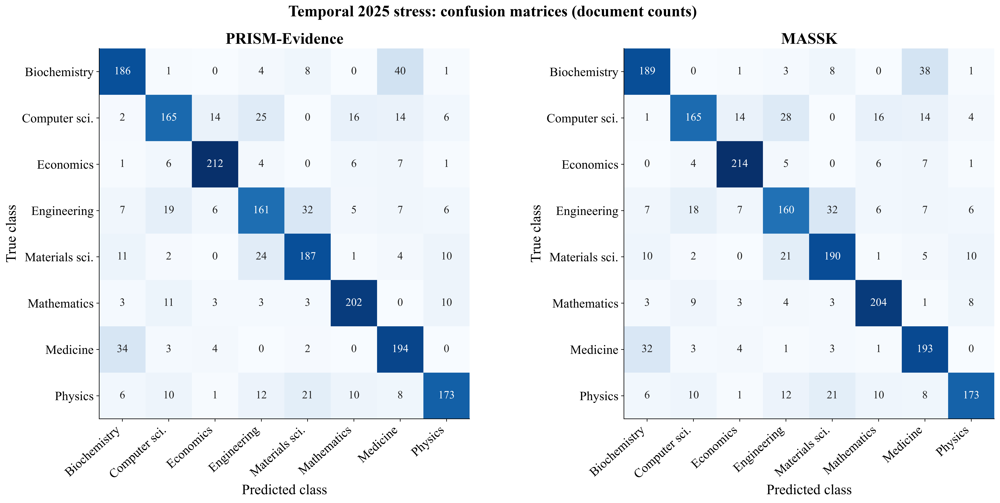

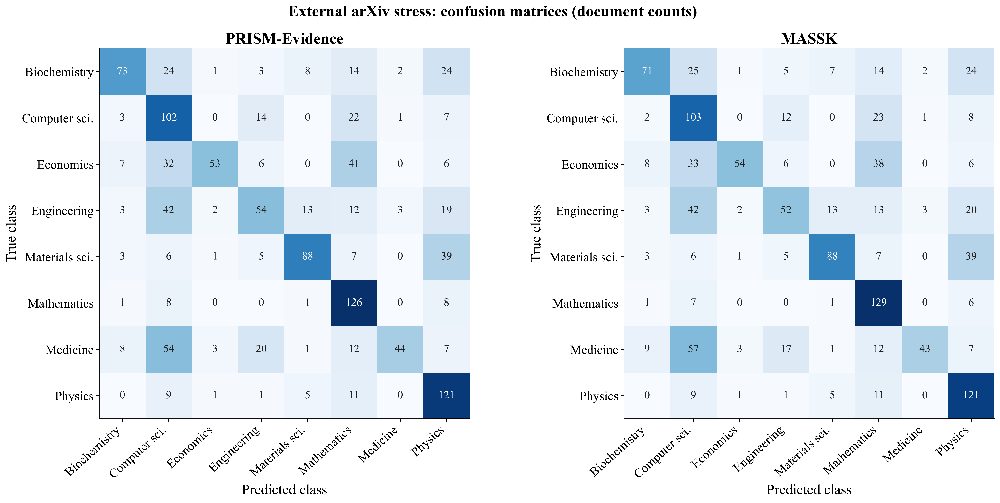

In [33]:
short_class_names = [
    'Biochemistry',
    'Computer sci.',
    'Economics',
    'Engineering',
    'Materials sci.',
    'Mathematics',
    'Medicine',
    'Physics',
]

for cohort, stem in [
    ('Temporal 2025 stress', 'retrospective_stress_confusion_temporal'),
    ('External arXiv stress', 'retrospective_stress_confusion_external'),
]:
    fig, axes = plt.subplots(1, 2, figsize=(19.0, 9.4))
    for ax, model in zip(axes, ['PRISM-Evidence', 'MASSK']):
        part = stress_confusion[
            stress_confusion['Cohort'].eq(cohort)
            & stress_confusion['Model'].eq(model)
        ]
        matrix = part.pivot(
            index='True class ID',
            columns='Predicted class ID',
            values='Count',
        ).reindex(index=np.arange(8), columns=np.arange(8)).to_numpy(int)
        image = ax.imshow(matrix, cmap='Blues', aspect='equal')
        threshold = matrix.max() * 0.55
        for row in range(8):
            for column in range(8):
                ax.text(
                    column,
                    row,
                    f'{matrix[row, column]}',
                    ha='center',
                    va='center',
                    fontsize=14,
                    color='white' if matrix[row, column] > threshold else PALETTE['black'],
                )
        ax.set_title(model, fontsize=20, fontweight='bold')
        ax.set_xlabel('Predicted class', fontsize=18)
        ax.set_ylabel('True class', fontsize=18)
        ax.set_xticks(np.arange(8), short_class_names, rotation=42, ha='right', fontsize=16)
        ax.set_yticks(np.arange(8), short_class_names, fontsize=16)
        ax.grid(False)
    fig.suptitle(f'{cohort}: confusion matrices (document counts)', fontsize=20, fontweight='bold')
    fig.subplots_adjust(left=0.11, right=0.99, bottom=0.21, top=0.90, wspace=0.22)
    save_figure(fig, stem)

In [34]:
def dominant_confusion(cohort, model):
    part = stress_confusion[
        stress_confusion['Cohort'].eq(cohort)
        & stress_confusion['Model'].eq(model)
        & stress_confusion['True class ID'].ne(stress_confusion['Predicted class ID'])
    ].sort_values('Count', ascending=False)
    top = part.iloc[0]
    return {
        'pair': f"{top['True class']} → {top['Predicted class']}",
        'count': int(top['Count']),
        'errors': int(part['Count'].sum()),
    }

error_text = []
for cohort in ['Temporal 2025 stress', 'External arXiv stress']:
    prism_error = dominant_confusion(cohort, 'PRISM-Evidence')
    massk_error = dominant_confusion(cohort, 'MASSK')
    error_text.append(
        f"On **{cohort}**, the dominant PRISM confusion was "
        f"**{prism_error['pair']}** ({prism_error['count']} documents), while the "
        f"dominant MASSK confusion was **{massk_error['pair']}** "
        f"({massk_error['count']} documents). Total errors changed from "
        f"**{prism_error['errors']}** to **{massk_error['errors']}**."
    )
display(
    Markdown(
        '**Article-ready error interpretation.** '
        + ' '.join(error_text)
        + ' The dominant confusion family remained unchanged in both cohorts. '
        'Thus, MASSK slightly reduced the temporal error count but did not remove '
        'the main semantic ambiguity; under external source shift it did not reduce '
        'the total number of classification errors.'
    )
)

**Article-ready error interpretation.** On **Temporal 2025 stress**, the dominant PRISM confusion was **Biochemistry, genetics and molecular biology → Medicine** (40 documents), while the dominant MASSK confusion was **Biochemistry, genetics and molecular biology → Medicine** (38 documents). Total errors changed from **434** to **426**. On **External arXiv stress**, the dominant PRISM confusion was **Medicine → Computer science** (54 documents), while the dominant MASSK confusion was **Medicine → Computer science** (57 documents). Total errors changed from **520** to **520**. The dominant confusion family remained unchanged in both cohorts. Thus, MASSK slightly reduced the temporal error count but did not remove the main semantic ambiguity; under external source shift it did not reduce the total number of classification errors.

### 12.4. Retrieval quality, vocabulary growth, and computational efficiency

Retrieval relevance is a transparent **class-label proxy**, not a human relevance
judgment. Encoding times come from the original CUDA preprocessing manifests and
were not repeated. Index construction, classifier-head inference, and exact
retrieval were measured in this run. Therefore, cached-head latency must not be
reported as full end-to-end document latency.

In [35]:

retrieval_view = stress_retrieval.copy()
retrieval_view['Estimate [95% CI]'] = retrieval_view.apply(
    lambda row: (
        f"{row['Estimate']:.4f} "
        f"[{row['CI lower']:.4f}, {row['CI upper']:.4f}]"
    ),
    axis=1,
)
display(
    retrieval_view[
        ['Cohort', 'Relevance definition', 'Metric', 'Estimate [95% CI]']
    ].style.hide(axis='index')
    .set_caption('Exact dual-view retrieval with class-label proxy relevance')
)
heaps_document = pd.read_csv(
    TABLES / 'retrospective_stress_heaps_law_document_bootstrap.csv'
)
display(
    heaps_document[
        [
            'Corpus',
            'Documents',
            'Final cumulative tokens',
            'Final vocabulary size',
            'Heaps beta',
            'CI lower',
            'CI upper',
            'Bootstrap iterations',
            'Resampling unit',
        ]
    ].style.hide(axis='index')
    .format(
        {
            'Documents': '{:,.0f}',
            'Final cumulative tokens': '{:,.0f}',
            'Final vocabulary size': '{:,.0f}',
            'Heaps beta': '{:.4f}',
            'CI lower': '{:.4f}',
            'CI upper': '{:.4f}',
            'Bootstrap iterations': '{:,.0f}',
        }
    )
    .set_caption("Heaps' law with 95% document-order sensitivity interval")
)


Cohort,Relevance definition,Metric,Estimate [95% CI]
Temporal 2025 stress,same eight-class thematic label (proxy),Precision@5,"0.6946 [0.6795, 0.7085]"
Temporal 2025 stress,same eight-class thematic label (proxy),Hit@5,"0.9101 [0.8976, 0.9232]"
Temporal 2025 stress,same eight-class thematic label (proxy),MRR@10,"0.8031 [0.7880, 0.8188]"
Temporal 2025 stress,same eight-class thematic label (proxy),nDCG@10,"0.6856 [0.6716, 0.6996]"
External arXiv stress,same eight-class thematic label (proxy),Precision@5,"0.5236 [0.5019, 0.5456]"
External arXiv stress,same eight-class thematic label (proxy),Hit@5,"0.7341 [0.7087, 0.7578]"
External arXiv stress,same eight-class thematic label (proxy),MRR@10,"0.6139 [0.5884, 0.6390]"
External arXiv stress,same eight-class thematic label (proxy),nDCG@10,"0.5217 [0.4997, 0.5433]"


Corpus,Documents,Final cumulative tokens,Final vocabulary size,Heaps beta,CI lower,CI upper,Bootstrap iterations,Resampling unit
development training partition,"3,825","760,582","77,100",0.7093,0.6936,0.7120,500,random permutation of training documents


In [36]:
e2e_timing = pd.read_csv(TABLES / 'retrospective_stress_end_to_end_timing.csv')
e2e_latency = pd.read_csv(TABLES / 'retrospective_stress_end_to_end_latency.csv')
e2e_resources = pd.read_csv(TABLES / 'retrospective_stress_end_to_end_resources.csv')
e2e_equivalence = pd.read_csv(TABLES / 'retrospective_stress_end_to_end_equivalence.csv')
e2e_receipt = json.loads(
    (MODELS / 'retrospective_stress_end_to_end_benchmark_receipt.json').read_text()
)
assert e2e_receipt['status'] == 'completed'
assert e2e_receipt['equivalence_pass'] is True
assert e2e_equivalence['Pass'].all()
assert e2e_receipt['protocol_sha256'] == stress_protocol['protocol_sha256']
assert e2e_receipt['model_bundle_sha256'] == sha256(
    (MODELS / 'retrospective_stress_model_bundle_v2.pt').read_bytes()
).hexdigest()
for filename, expected_digest in e2e_receipt['output_sha256'].items():
    artifact_path = TABLES / filename
    assert artifact_path.exists(), artifact_path
    assert sha256(artifact_path.read_bytes()).hexdigest() == expected_digest

batch_e2e = e2e_timing[
    e2e_timing['Stage'].eq('Raw-text-to-MASSK end-to-end batch')
][
    [
        'Scope',
        'Documents',
        'Seconds',
        'Documents per second',
        'Milliseconds per document',
    ]
].copy()
display(
    batch_e2e.style.hide(axis='index')
    .format(
        {
            'Documents': '{:,.0f}',
            'Seconds': '{:.3f}',
            'Documents per second': '{:.2f}',
            'Milliseconds per document': '{:.3f}',
        }
    )
    .set_caption('Same-session raw-text-to-MASSK batched throughput')
)

batch1_e2e = e2e_latency[e2e_latency['Stage'].eq('End-to-end')][
    [
        'Cohort',
        'Measured documents',
        'Median (ms)',
        'P95 (ms)',
        'Minimum (ms)',
        'Maximum (ms)',
    ]
]
display(
    batch1_e2e.style.hide(axis='index')
    .format(
        {
            'Measured documents': '{:,.0f}',
            'Median (ms)': '{:.2f}',
            'P95 (ms)': '{:.2f}',
            'Minimum (ms)': '{:.2f}',
            'Maximum (ms)': '{:.2f}',
        }
    )
    .set_caption('Warmed batch-1 raw-text-to-MASSK latency')
)

setup_view = e2e_timing[
    e2e_timing['Scope'].eq('Reusable setup')
    & e2e_timing['Stage'].isin(
        [
            'Qwen3 reference encoding',
            'SPECTER2 reference encoding',
            'Exact dual-view index construction',
            'Reusable setup total',
        ]
    )
][['Stage', 'Documents', 'Seconds', 'Documents per second']]
display(
    setup_view.style.hide(axis='index')
    .format(
        {
            'Documents': '{:,.0f}',
            'Seconds': '{:.3f}',
            'Documents per second': '{:.2f}',
        }
    )
    .set_caption('One-time reusable reference preparation')
)

resource_items = [
    'GPU model',
    'Qwen3 peak allocated GPU memory (GiB)',
    'Main-process peak allocated GPU memory (GiB)',
    'SPECTER2-worker peak allocated GPU memory (GiB)',
    'Combined allocated-memory upper bound (GiB)',
    'Full-pipeline peak process RAM (GiB)',
    'Transformers (Qwen3 runtime)',
    'Sentence-Transformers',
    'Transformers (SPECTER2 worker)',
    'Adapters',
    'Tokenizers',
    'CPU model',
    'CPU fallback',
]
resource_reader = e2e_resources[e2e_resources['Item'].isin(resource_items)]
display(
    resource_reader.style.hide(axis='index')
    .set_caption('Same-session hardware, software, and resource measurements')
)

embedding_equivalence = e2e_equivalence[
    e2e_equivalence['Comparison'].str.contains('embedding')
][
    [
        'Cohort',
        'Comparison',
        'N',
        'Minimum',
        'Median',
        'Maximum',
        'Acceptance threshold',
        'Pass',
    ]
]
display(
    embedding_equivalence.style.hide(axis='index')
    .format(
        {
            'N': '{:,.0f}',
            'Minimum': '{:.6f}',
            'Median': '{:.6f}',
            'Maximum': '{:.6f}',
        },
        na_rep='—',
    )
    .map(lambda value: 'font-weight: bold; color: #2F6B3A' if value is True else '')
    .set_caption('Fresh-to-frozen embedding cosine equivalence')
)

posterior_equivalence = e2e_equivalence[
    e2e_equivalence['Comparison'].str.contains('posterior')
][
    [
        'Cohort',
        'Comparison',
        'N',
        'Label agreement',
        'Maximum absolute probability difference',
        'Acceptance threshold',
        'Pass',
    ]
]
display(
    posterior_equivalence.style.hide(axis='index')
    .format(
        {
            'N': '{:,.0f}',
            'Label agreement': '{:.6f}',
            'Maximum absolute probability difference': '{:.3e}',
        },
        na_rep='—',
    )
    .map(lambda value: 'font-weight: bold; color: #2F6B3A' if value is True else '')
    .set_caption('Fresh-to-frozen posterior and label equivalence')
)

display(
    Markdown(
        f'''**Efficiency interpretation.** The temporal cohort completed the direct
        raw-text-to-MASSK batch path in **{batch_e2e.iloc[0]['Seconds']:.3f} s**
        ({batch_e2e.iloc[0]['Documents per second']:.2f} documents/s), while the
        external arXiv cohort required **{batch_e2e.iloc[1]['Seconds']:.3f} s**
        ({batch_e2e.iloc[1]['Documents per second']:.2f} documents/s). These values
        include tokenization, CPU-to-GPU transfer, both pinned encoders,
        PRISM-Evidence, exact Top-5 retrieval, and the MASSK residual. Model loading
        and development-reference preparation are reported separately. The warmed
        batch-1 median and P95 characterize single-document latency without
        disguising batched throughput as interactive latency. Artifact hashes,
        protocol identity, model-bundle identity, embedding cosines, posterior
        differences, and label agreement are all checked before these measurements
        are displayed.'''
    )
)


Scope,Documents,Seconds,Documents per second,Milliseconds per document
Temporal 2025 stress,"1,914",61.583,31.08,32.175
External arXiv stress,"1,181",33.124,35.65,28.047


Cohort,Measured documents,Median (ms),P95 (ms),Minimum (ms),Maximum (ms)
Temporal 2025 stress,32,64.10,84.10,60.36,91.90
External arXiv stress,32,67.50,87.46,60.06,93.61


Stage,Documents,Seconds,Documents per second
Qwen3 reference encoding,"6,708",168.850,39.73
SPECTER2 reference encoding,"6,708",37.667,178.09
Exact dual-view index construction,"6,708",0.031,215586.46
Reusable setup total,"6,708",216.857,30.93


Item,Value,Scope
GPU model,NVIDIA GeForce RTX 5070 Laptop GPU,same benchmark session
Qwen3 peak allocated GPU memory (GiB),2.788129,after Qwen3 reference encoding
Main-process peak allocated GPU memory (GiB),2.841302,"Qwen3, fixed heads, and exact index"
SPECTER2-worker peak allocated GPU memory (GiB),0.922384,persistent adapter worker
Combined allocated-memory upper bound (GiB),3.763687,"sum of per-process peaks; conservative, not necessarily simultaneous"
Full-pipeline peak process RAM (GiB),2.731422,entire same-session benchmark
CPU model,Intel(R) Core(TM) i7-14650HX,same benchmark session
CPU fallback,Prohibited and not used,all neural and retrieval inference on CUDA
Transformers (Qwen3 runtime),5.12.1,main benchmark process
Sentence-Transformers,5.6.0,main benchmark process


Cohort,Comparison,N,Minimum,Median,Maximum,Acceptance threshold,Pass
Development reference,Qwen3 fresh versus stored embedding,"6,708",0.999785,1.000000,1.000000,minimum >= 0.999,True
Development reference,SPECTER2 fresh versus stored embedding,"6,708",1.000000,1.000000,1.000000,minimum >= 0.999,True
Temporal 2025 stress,Qwen3 fresh versus stored embedding,"1,914",0.999786,1.000000,1.000000,minimum >= 0.999,True
Temporal 2025 stress,SPECTER2 fresh versus stored embedding,"1,914",1.000000,1.000000,1.000000,minimum >= 0.999,True
External arXiv stress,Qwen3 fresh versus stored embedding,"1,181",0.999795,1.000000,1.000000,minimum >= 0.999,True
External arXiv stress,SPECTER2 fresh versus stored embedding,"1,181",1.000000,1.000000,1.000000,minimum >= 0.999,True


Cohort,Comparison,N,Label agreement,Maximum absolute probability difference,Acceptance threshold,Pass
Temporal 2025 stress,PRISM-Evidence fresh versus stored posterior,"1,914",1.000000,2.730e-03,label agreement >= 0.999,True
Temporal 2025 stress,MASSK fresh versus stored posterior,"1,914",1.000000,2.617e-03,label agreement >= 0.999,True
External arXiv stress,PRISM-Evidence fresh versus stored posterior,"1,181",1.000000,7.160e-04,label agreement >= 0.999,True
External arXiv stress,MASSK fresh versus stored posterior,"1,181",1.000000,5.782e-04,label agreement >= 0.999,True


**Efficiency interpretation.** The temporal cohort completed the direct
        raw-text-to-MASSK batch path in **61.583 s**
        (31.08 documents/s), while the
        external arXiv cohort required **33.124 s**
        (35.65 documents/s). These values
        include tokenization, CPU-to-GPU transfer, both pinned encoders,
        PRISM-Evidence, exact Top-5 retrieval, and the MASSK residual. Model loading
        and development-reference preparation are reported separately. The warmed
        batch-1 median and P95 characterize single-document latency without
        disguising batched throughput as interactive latency. Artifact hashes,
        protocol identity, model-bundle identity, embedding cosines, posterior
        differences, and label agreement are all checked before these measurements
        are displayed.

In [37]:
temporal_retrieval = stress_retrieval[
    stress_retrieval['Cohort'].eq('Temporal 2025 stress')
].set_index('Metric')
external_retrieval = stress_retrieval[
    stress_retrieval['Cohort'].eq('External arXiv stress')
].set_index('Metric')
heaps_row = stress_heaps.iloc[0]
display(
    Markdown(
        f'''
**Article-ready interpretation.** The class-proxy retrieval signal weakened under
source shift: nDCG@10 decreased from
**{temporal_retrieval.loc['nDCG@10', 'Estimate']:.4f}** on temporal OpenAlex to
**{external_retrieval.loc['nDCG@10', 'Estimate']:.4f}** on external arXiv.
This decline is consistent with the external reliability degradation of the
retrieval residual and should be treated as a mechanism-level limitation.
The training vocabulary followed a sublinear Heaps relation with
β = **{heaps_row['Heaps beta']:.4f}**
[{heaps_row['CI lower']:.4f}, {heaps_row['CI upper']:.4f}]. Because the Heaps
checkpoints are cumulative, this interval is descriptive rather than an
independent-document inferential interval.
'''
    )
)


**Article-ready interpretation.** The class-proxy retrieval signal weakened under
source shift: nDCG@10 decreased from
**0.6856** on temporal OpenAlex to
**0.5217** on external arXiv.
This decline is consistent with the external reliability degradation of the
retrieval residual and should be treated as a mechanism-level limitation.
The training vocabulary followed a sublinear Heaps relation with
β = **0.7093**
[0.6884, 0.7198]. Because the Heaps
checkpoints are cumulative, this interval is descriptive rather than an
independent-document inferential interval.



### 12.5. Publication conclusion and remaining confirmation boundary

The fixed pipeline has now been measured from raw text to the MASSK posterior in one
hardware session. The saved evidence includes aggregate and per-class classification
metrics, document-bootstrap intervals for precision, recall, and F1, calibration and
selective-risk metrics, paired MASSK–PRISM contrasts, retrieval quality, confusion
matrices, a complete frozen specification, a document-order sensitivity interval for Heaps' law,
component timings, direct batched end-to-end throughput, warmed batch-1 median/P95
latency, and peak resource measurements. Fresh Qwen3 and SPECTER2 representations
and final decisions passed the pre-specified equivalence checks against the frozen
saved experiment.

The scientific conclusion remains deliberately bounded. MASSK provides an
interpretable class-wise retrieval-residual mechanism and shows a small,
statistically unresolved temporal classification gain. On the retrospective
external arXiv cohort, it does not improve Macro-F1 and significantly worsens NLL,
multiclass Brier score, and ECE-15 relative to PRISM-Evidence. These results support
the methodological and applied novelty of the proposed mechanism, but they do not
establish universal superiority or independent confirmation. Both stress cohorts
were present in the project before the final lock; a genuinely prospective cohort
collected after model and protocol freezing remains necessary for a confirmatory
claim.
